# Explore "swat_dataset.csv"

### This notebook is used to confirm the file's location, read the data, and understand its structure before we create the tables.

#SWaT Data Exploration

## Objetivo
Explorar o dataset SWaT antes de iniciar o pipeline de dados.

## Tarefas
1. Confirmar o catálogo, schema e caminho de origem.
2. Ler o CSV com PySpark.
3. Verificar dimensões, colunas e tipos de dados.
4. Investigar valores nulos, duplicados e timestamps.
5. Documentar os problemas de qualidade identificados.



In [0]:

landing_path = "/Volumes/first_catalog/default/first_volume/swat_dataset_merged.csv"

catalog = "first_catalog"
schema = "default"

# 2. Verificar se conseguimos ler o CSV

df_raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "false")
    .option("mode", "PERMISSIVE")
    .csv(landing_path)
)

# 3. Explorar a estrutura

print("Número de registos:", df_raw.count())
print("Número de colunas:", len(df_raw.columns))
print("Colunas disponíveis:", df_raw.columns)

display(df_raw.limit(10))


Número de registos: 1441719
Número de colunas: 53
Colunas disponíveis: [' Timestamp', 'FIT101', 'LIT101', ' MV101', 'P101', 'P102', ' AIT201', 'AIT202', 'AIT203', 'FIT201', ' MV201', ' P201', ' P202', 'P203', ' P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', ' MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'Normal/Attack']


Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,P201,P202,P203,P204,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
28/12/2015 10:00:00 AM,2.427057,522.8467,2.0,2,1,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2,1.0,2,1,19.74838,2.206835,956.1651,1,2,1.0,1,1,2,148.808,156.0882,1.713517,942.0662,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723789,1.279621,0.7352687,0.3077859,2,1,250.8652,1.649953,189.5988,0.000128152,1,1,1,Normal
28/12/2015 10:00:01 AM,2.446274,522.886,2.0,2,1,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2,1.0,2,1,19.74838,2.208244,956.1651,1,2,1.0,1,1,2,148.808,156.0882,1.715952,942.0277,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723789,1.297554,0.7352687,0.3077859,2,1,250.8652,1.649953,189.6789,0.000128152,1,1,1,Normal
28/12/2015 10:00:02 AM,2.489191,522.8467,2.0,2,1,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,956.4855,1,2,1.0,1,1,2,148.808,156.0882,1.715952,941.8739,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723404,1.293967,0.7352687,0.3086186,2,1,250.8812,1.649953,189.6789,0.000128152,1,1,1,Normal
28/12/2015 10:00:03 AM,2.53435,522.9645,2.0,2,1,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,956.806,1,2,1.0,1,1,2,148.808,156.0882,1.71467,941.797,1,2,1,1,2,7.878621,145.0141,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2,1,250.8812,1.649953,189.6148,0.000128152,1,1,1,Normal
28/12/2015 10:00:04 AM,2.56926,523.4748,2.0,2,1,262.0161,8.394514,328.6337,2.443085,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,957.0864,1,2,1.0,1,1,2,148.808,156.0882,1.71467,942.22,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2,1,250.8812,1.649953,189.5027,0.000128152,1,1,1,Normal
28/12/2015 10:00:05 AM,2.609294,523.8673,2.0,2,1,262.0161,8.394514,328.6337,2.44411,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.207347,957.1664,1,2,1.0,1,1,2,148.808,155.96,1.71467,942.6429,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.272704,0.7352687,0.3086186,2,1,250.753,1.649953,189.5027,0.000128152,1,1,1,Normal
28/12/2015 10:00:06 AM,2.637158,524.1028,2.0,2,1,262.0161,8.394514,328.6337,2.44411,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.210037,957.0062,1,2,1.0,1,1,2,148.808,155.96,1.713004,942.7582,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.270142,0.7352687,0.3086186,2,1,250.5928,1.649953,189.5027,0.000128152,1,1,1,Normal
28/12/2015 10:00:07 AM,2.652211,524.2206,2.0,2,1,262.0161,8.394514,328.6337,2.441803,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.210037,957.2866,1,2,1.0,1,1,2,148.808,155.96,1.713004,943.1043,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.262329,0.7352687,0.3086186,2,1,250.5928,1.649953,189.5027,0.000128152,1,1,1,Normal
28/12/2015 10:00:08 AM,2.655735,524.4954,2.0,2,1,262.0161,8.394514,328.6337,2.441803,2.0,1.0,1.0,2,1.0,2,1,19.66195,2.210037,957.6071,1,2,1.0,1,1,2,148.808,155.96,1.71262,943.3735,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.270398,0.7352687,0.3086186,2,1,250.9132,1.649953,189.5027,0.000128152,1,1,1,Normal
28/12/2015 10:00:09 AM,2.64997,524.0636,2.0,2,1,262.0161,8.394514,328.6337,2.441803,2.0,1.0,1.0,2,1.0,2,1,19.66195,2.210037,957.2866,1,2,1.0,1,1,2,148.808,155.96,1.71262,943.6042,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.726224,1.281158,0.7352687,0.3084905,2,1,250.9132,1.649953,189.5668,0.000128152,1,1,1,Normal


### Diagnóstico inicial

In [0]:

from pyspark.sql import functions as F

# Normalizar os nomes das colunas
# Remover espaços no início e no fim
df_raw = df_raw.toDF(*[c.strip() for c in df_raw.columns])

#  Verificar se existem nomes duplicados após remover espaços
if len(df_raw.columns) != len(set(df_raw.columns)):
    raise ValueError(
        "Existem nomes de colunas duplicados após remover espaços."
    )

print("Colunas após limpeza:")
print(df_raw.columns)

# 4. Verificar a distribuição do target
target = "Normal/Attack"

if target not in df_raw.columns:
    raise ValueError(f"A coluna {target} não foi encontrada.")

display(
    df_raw.groupBy(target)
          .count()
          .orderBy(F.desc("count"))
)


Colunas após limpeza:
['Timestamp', 'FIT101', 'LIT101', 'MV101', 'P101', 'P102', 'AIT201', 'AIT202', 'AIT203', 'FIT201', 'MV201', 'P201', 'P202', 'P203', 'P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'Normal/Attack']


Normal/Attack,count
Normal,1387098
Attack,54621


##### Analisar o dataset sem converter o timestamp

##### Criar a tabela Bronze

In [0]:

# Projeto SWaT — Camada Bronze

catalog = "first_catalog"
schema = "default"
tabela_bronze = f"{catalog}.{schema}.bronze_swat"

# Garantir que os nomes das colunas não têm espaços exteriores
df_bronze = df_teste.toDF(
    *[c.strip() for c in df_teste.columns]
)

# Verificar a existência da coluna target
if "Normal/Attack" not in df_bronze.columns:
    raise ValueError("A coluna Normal/Attack não foi encontrada.")

# Guardar como tabela Delta
(
    df_bronze.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(tabela_bronze)
)

print("Tabela Bronze criada:", tabela_bronze)
print("Número de registos:", spark.table(tabela_bronze).count())


---------------------------------------------------------------------------
DateTimeException                         Traceback (most recent call last)
File <command-8961626724268582>, line 23
     15     raise ValueError("A coluna Normal/Attack não foi encontrada.")
     17 # Guardar como tabela Delta
     18 (
     19     df_bronze.write
     20     .format("delta")
     21     .mode("overwrite")
     22     .option("overwriteSchema", "true")
---> 23     .saveAsTable(tabela_bronze)
     24 )
     26 print("Tabela Bronze criada:", tabela_bronze)
     27 print("Número de registos:", spark.table(tabela_bronze).count())

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/readwriter.py:737, in DataFrameWriter.saveAsTable(self, name, format, mode, partitionBy, **options)
    735 self._write.table_name = name
    736 self._write.table_save_method = "save_as_table"
--> 737 _, _, ei = self._spark.client.execute_command(
    738     self._write.command(self._spark.client)

Voltar a ler o CSV de forma limpa

In [0]:

# Projeto SWaT — Leitura da camada Bronze

from pyspark.sql import functions as F

catalog = "first_catalog"
schema = "default"

landing_path = (
    "/Volumes/first_catalog/default/first_volume/"
    "swat_dataset_merged.csv"
)

df_bronze = (
    spark.read
    .format("csv")
    .option("header", "true")
    .option("inferSchema", "false")
    .option("sep", ",")
    .option("mode", "PERMISSIVE")
    .load(landing_path)
)

# Limpar espaços no início e no fim dos nomes das colunas
df_bronze = df_bronze.toDF(
    *[c.strip() for c in df_bronze.columns]
)

print("Número de colunas:", len(df_bronze.columns))
print("Colunas iniciais:", df_bronze.columns[:5])
print("Coluna target encontrada:", "Normal/Attack" in df_bronze.columns)

display(df_bronze.limit(5))


Número de colunas: 53
Colunas iniciais: ['Timestamp', 'FIT101', 'LIT101', 'MV101', 'P101']
Coluna target encontrada: True


Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,P201,P202,P203,P204,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
28/12/2015 10:00:00 AM,2.427057,522.8467,2.0,2,1,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2,1.0,2,1,19.74838,2.206835,956.1651,1,2,1.0,1,1,2,148.808,156.0882,1.713517,942.0662,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723789,1.279621,0.7352687,0.3077859,2,1,250.8652,1.649953,189.5988,0.000128152,1,1,1,Normal
28/12/2015 10:00:01 AM,2.446274,522.886,2.0,2,1,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2,1.0,2,1,19.74838,2.208244,956.1651,1,2,1.0,1,1,2,148.808,156.0882,1.715952,942.0277,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723789,1.297554,0.7352687,0.3077859,2,1,250.8652,1.649953,189.6789,0.000128152,1,1,1,Normal
28/12/2015 10:00:02 AM,2.489191,522.8467,2.0,2,1,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,956.4855,1,2,1.0,1,1,2,148.808,156.0882,1.715952,941.8739,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723404,1.293967,0.7352687,0.3086186,2,1,250.8812,1.649953,189.6789,0.000128152,1,1,1,Normal
28/12/2015 10:00:03 AM,2.53435,522.9645,2.0,2,1,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,956.806,1,2,1.0,1,1,2,148.808,156.0882,1.71467,941.797,1,2,1,1,2,7.878621,145.0141,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2,1,250.8812,1.649953,189.6148,0.000128152,1,1,1,Normal
28/12/2015 10:00:04 AM,2.56926,523.4748,2.0,2,1,262.0161,8.394514,328.6337,2.443085,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,957.0864,1,2,1.0,1,1,2,148.808,156.0882,1.71467,942.22,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2,1,250.8812,1.649953,189.5027,0.000128152,1,1,1,Normal


##### Gravar a tabela Bronze

In [0]:

# Projeto SWaT — Gravar a camada Bronze

catalog = "first_catalog"
schema = "default"
tabela_bronze = f"{catalog}.{schema}.bronze_swat"

# Confirmar que a coluna target existe
if "Normal/Attack" not in df_bronze.columns:
    raise ValueError("A coluna Normal/Attack não foi encontrada.")

# Verificar se a tabela já existe
if spark.catalog.tableExists(tabela_bronze):
    print(f"A tabela {tabela_bronze} já existe.")
    print("Não foi substituída para proteger os dados existentes.")
else:
    (
        df_bronze.write
        .format("delta")
        .saveAsTable(tabela_bronze)
    )
    print("Tabela Bronze criada:", tabela_bronze)

# Validar a tabela persistida
df_validacao = spark.table(tabela_bronze)

print("Número de registos:", df_validacao.count())
print("Número de colunas:", len(df_validacao.columns))

display(df_validacao.limit(5))



Tabela Bronze criada: first_catalog.default.bronze_swat
Número de registos: 1441719
Número de colunas: 53


Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,P201,P202,P203,P204,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
28/12/2015 10:00:00 AM,2.427057,522.8467,2.0,2,1,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2,1.0,2,1,19.74838,2.206835,956.1651,1,2,1.0,1,1,2,148.808,156.0882,1.713517,942.0662,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723789,1.279621,0.7352687,0.3077859,2,1,250.8652,1.649953,189.5988,0.000128152,1,1,1,Normal
28/12/2015 10:00:01 AM,2.446274,522.886,2.0,2,1,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2,1.0,2,1,19.74838,2.208244,956.1651,1,2,1.0,1,1,2,148.808,156.0882,1.715952,942.0277,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723789,1.297554,0.7352687,0.3077859,2,1,250.8652,1.649953,189.6789,0.000128152,1,1,1,Normal
28/12/2015 10:00:02 AM,2.489191,522.8467,2.0,2,1,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,956.4855,1,2,1.0,1,1,2,148.808,156.0882,1.715952,941.8739,1,2,1,1,2,7.878621,145.1166,264.5475,12.03538,1.723404,1.293967,0.7352687,0.3086186,2,1,250.8812,1.649953,189.6789,0.000128152,1,1,1,Normal
28/12/2015 10:00:03 AM,2.53435,522.9645,2.0,2,1,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,956.806,1,2,1.0,1,1,2,148.808,156.0882,1.71467,941.797,1,2,1,1,2,7.878621,145.0141,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2,1,250.8812,1.649953,189.6148,0.000128152,1,1,1,Normal
28/12/2015 10:00:04 AM,2.56926,523.4748,2.0,2,1,262.0161,8.394514,328.6337,2.443085,2.0,1.0,1.0,2,1.0,2,1,19.69076,2.208628,957.0864,1,2,1.0,1,1,2,148.808,156.0882,1.71467,942.22,1,2,1,1,2,7.878621,144.8859,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2,1,250.8812,1.649953,189.5027,0.000128152,1,1,1,Normal


##### Validar a tabela Bronze

In [0]:

# Projeto SWaT — Validação da camada Bronze

tabela_bronze = "first_catalog.default.bronze_swat"

# Ler a tabela persistida, e não apenas o DataFrame em memória
df_bronze_validacao = spark.table(tabela_bronze)

print("Número de registos:", df_bronze_validacao.count())
print("Número de colunas:", len(df_bronze_validacao.columns))

print("Timestamp existe:", "Timestamp" in df_bronze_validacao.columns)
print("Target existe:", "Normal/Attack" in df_bronze_validacao.columns)

display(
    df_bronze_validacao
    .select("Timestamp", "FIT101", "LIT101", "Normal/Attack")
    .limit(5)
)


Número de registos: 1441719
Número de colunas: 53
Timestamp existe: True
Target existe: True


Timestamp,FIT101,LIT101,Normal/Attack
28/12/2015 10:00:00 AM,2.427057,522.8467,Normal
28/12/2015 10:00:01 AM,2.446274,522.886,Normal
28/12/2015 10:00:02 AM,2.489191,522.8467,Normal
28/12/2015 10:00:03 AM,2.53435,522.9645,Normal
28/12/2015 10:00:04 AM,2.56926,523.4748,Normal


##### Investigar o formato do timestamp

In [0]:

from pyspark.sql import functions as F

tabela_bronze = "first_catalog.default.bronze_swat"

df_bronze = spark.table(tabela_bronze)

# Selecionar apenas alguns timestamps para testar a conversão
df_teste_timestamp = (
    df_bronze
    .select(F.trim(F.col("Timestamp")).alias("timestamp_original"))
    .limit(10)
    .withColumn(
        "timestamp_convertido",
        F.try_to_timestamp(
            F.col("timestamp_original"),
            F.lit("dd/MM/yyyy h:mm:ss a")
        )
    )
)

display(df_teste_timestamp)


timestamp_original,timestamp_convertido
22/12/2015 5:36:02 PM,2015-12-22T17:36:02.000Z
22/12/2015 5:36:03 PM,2015-12-22T17:36:03.000Z
22/12/2015 5:36:04 PM,2015-12-22T17:36:04.000Z
22/12/2015 5:36:05 PM,2015-12-22T17:36:05.000Z
22/12/2015 5:36:06 PM,2015-12-22T17:36:06.000Z
22/12/2015 5:36:07 PM,2015-12-22T17:36:07.000Z
22/12/2015 5:36:08 PM,2015-12-22T17:36:08.000Z
22/12/2015 5:36:09 PM,2015-12-22T17:36:09.000Z
22/12/2015 5:36:10 PM,2015-12-22T17:36:10.000Z
22/12/2015 5:36:11 PM,2015-12-22T17:36:11.000Z


##### Preparar para camada Silver
Nesta etapa vamos:
1. Ler a tabela Bronze.
2. Limpar os nomes das colunas.
3. Converter Timestamp para um tipo de data/hora.
4. Converter as colunas dos sensores para tipos numéricos.
5. Normalizar a coluna-alvo para normal_attack.
6. Manter a Bronze intacta.

In [0]:

# Projeto SWaT — Preparação da camada Silver

from pyspark.sql import functions as F

tabela_bronze = "first_catalog.default.bronze_swat"
tabela_silver = "first_catalog.default.silver_swat"

df_bronze = spark.table(tabela_bronze)

# 1. Limpar espaços nos nomes das colunas
df_silver = df_bronze.toDF(
    *[c.strip() for c in df_bronze.columns]
)

# 2. Converter o timestamp com o formato confirmado
df_silver = df_silver.withColumn(
    "Timestamp",
    F.try_to_timestamp(
        F.trim(F.col("Timestamp")),
        F.lit("dd/MM/yyyy h:mm:ss a")
    )
)

# 3. Renomear a coluna-alvo para um nome mais simples
df_silver = df_silver.withColumnRenamed(
    "Normal/Attack",
    "normal_attack"
)

# 4. Converter todas as colunas dos sensores para números
colunas_excluir = {"Timestamp", "normal_attack"}

colunas_sensores = [
    c for c in df_silver.columns
    if c not in colunas_excluir
]

for coluna in colunas_sensores:
    df_silver = df_silver.withColumn(
        coluna,
        F.expr(f"try_cast(`{coluna}` AS DOUBLE)")
    )

# 5. Normalizar o texto da variável-alvo
df_silver = df_silver.withColumn(
    "normal_attack",
    F.upper(F.trim(F.col("normal_attack")))
)

print("Preparação da Silver concluída.")
print("Número de colunas:", len(df_silver.columns))

display(df_silver.limit(5))


Preparação da Silver concluída.
Número de colunas: 53


Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,P201,P202,P203,P204,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,normal_attack
2015-12-28T10:00:00.000Z,2.427057,522.8467,2.0,2.0,1.0,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2.0,1.0,2.0,1.0,19.74838,2.206835,956.1651,1.0,2.0,1.0,1.0,1.0,2.0,148.808,156.0882,1.713517,942.0662,1.0,2.0,1.0,1.0,2.0,7.878621,145.1166,264.5475,12.03538,1.723789,1.279621,0.7352687,0.3077859,2.0,1.0,250.8652,1.649953,189.5988,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:01.000Z,2.446274,522.886,2.0,2.0,1.0,262.0161,8.396437,328.6337,2.445391,2.0,1.0,1.0,2.0,1.0,2.0,1.0,19.74838,2.208244,956.1651,1.0,2.0,1.0,1.0,1.0,2.0,148.808,156.0882,1.715952,942.0277,1.0,2.0,1.0,1.0,2.0,7.878621,145.1166,264.5475,12.03538,1.723789,1.297554,0.7352687,0.3077859,2.0,1.0,250.8652,1.649953,189.6789,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:02.000Z,2.489191,522.8467,2.0,2.0,1.0,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2.0,1.0,2.0,1.0,19.69076,2.208628,956.4855,1.0,2.0,1.0,1.0,1.0,2.0,148.808,156.0882,1.715952,941.8739,1.0,2.0,1.0,1.0,2.0,7.878621,145.1166,264.5475,12.03538,1.723404,1.293967,0.7352687,0.3086186,2.0,1.0,250.8812,1.649953,189.6789,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:03.000Z,2.53435,522.9645,2.0,2.0,1.0,262.0161,8.394514,328.6337,2.442316,2.0,1.0,1.0,2.0,1.0,2.0,1.0,19.69076,2.208628,956.806,1.0,2.0,1.0,1.0,1.0,2.0,148.808,156.0882,1.71467,941.797,1.0,2.0,1.0,1.0,2.0,7.878621,145.0141,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2.0,1.0,250.8812,1.649953,189.6148,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:04.000Z,2.56926,523.4748,2.0,2.0,1.0,262.0161,8.394514,328.6337,2.443085,2.0,1.0,1.0,2.0,1.0,2.0,1.0,19.69076,2.208628,957.0864,1.0,2.0,1.0,1.0,1.0,2.0,148.808,156.0882,1.71467,942.22,1.0,2.0,1.0,1.0,2.0,7.878621,144.8859,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2.0,1.0,250.8812,1.649953,189.5027,1.28152E-4,1.0,1.0,1.0,NORMAL


##### Verificações de qualidade da Silver

In [0]:

# Projeto SWaT — Validação da qualidade da Silver

from pyspark.sql import functions as F

# 1. Contagem total de registos
total_registos = df_silver.count()

# 2. Timestamps nulos
timestamps_nulos = (
    df_silver
    .filter(F.col("Timestamp").isNull())
    .count()
)

# 3. Valores nulos na coluna-alvo
targets_nulos = (
    df_silver
    .filter(
        F.col("normal_attack").isNull()
        | (F.col("normal_attack") == "")
    )
    .count()
)

# 4. Verificar as classes da variável-alvo
print("Distribuição da variável-alvo:")
display(
    df_silver
    .groupBy("normal_attack")
    .count()
    .orderBy(F.desc("count"))
)

# 5. Contar valores nulos por coluna de sensor
colunas_sensores = [
    c for c in df_silver.columns
    if c not in {"Timestamp", "normal_attack"}
]

nulos_por_sensor = df_silver.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in colunas_sensores
])

print("Total de registos:", total_registos)
print("Timestamps nulos:", timestamps_nulos)
print("Targets nulos:", targets_nulos)

display(nulos_por_sensor)


Distribuição da variável-alvo:


normal_attack,count
NORMAL,1387098
ATTACK,54621


Total de registos: 1441719
Timestamps nulos: 140400
Targets nulos: 0


FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,P201,P202,P203,P204,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603
0,0,991800,0,0,991800,0,0,0,991800,991800,991800,0,991800,0,0,0,0,0,0,0,991800,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


##### Corrigir a preparação da Silver

In [0]:

# Projeto SWaT — Preparação corrigida da Silver

from pyspark.sql import functions as F

tabela_bronze = "first_catalog.default.bronze_swat"
tabela_silver = "first_catalog.default.silver_swat"

df_bronze = spark.table(tabela_bronze)

# 1. Limpar espaços nos nomes das colunas
df_silver = df_bronze.toDF(
    *[c.strip() for c in df_bronze.columns]
)

# 2. Converter timestamps com o formato validado
df_silver = df_silver.withColumn(
    "Timestamp",
    F.try_to_timestamp(
        F.trim(F.col("Timestamp")),
        F.lit("d/M/yyyy h:mm:ss a")
    )
)

# 3. Renomear a variável-alvo
df_silver = df_silver.withColumnRenamed(
    "Normal/Attack",
    "normal_attack"
)

# 4. Converter os sensores para números
colunas_sensores = [
    c for c in df_silver.columns
    if c not in {"Timestamp", "normal_attack"}
]

for coluna in colunas_sensores:
    df_silver = df_silver.withColumn(
        coluna,
        F.expr(f"try_cast(`{coluna}` AS DOUBLE)")
    )

# 5. Normalizar os valores da variável-alvo
df_silver = df_silver.withColumn(
    "normal_attack",
    F.upper(F.trim(F.col("normal_attack")))
)

print("Registos:", df_silver.count())
print(
    "Timestamps nulos:",
    df_silver.filter(F.col("Timestamp").isNull()).count()
)

print("Distribuição das classes:")
display(
    df_silver
    .groupBy("normal_attack")
    .count()
    .orderBy(F.desc("count"))
)


Registos: 1441719
Timestamps nulos: 0
Distribuição das classes:


normal_attack,count
NORMAL,1387098
ATTACK,54621


##### diagnóstico dos valores dos sensores

In [0]:
from pyspark.sql import functions as F

# Verificar os valores nulos na Silver após a conversão
sensores_suspeitos = [
    "MV101", "AIT201", "FIT201",
    "MV201", "P201", "MV302"
]

metricas_silver = []

for sensor in sensores_suspeitos:
    metricas_silver.append(
        F.sum(
            F.when(F.col(sensor).isNull(), 1).otherwise(0)
        ).alias(f"{sensor}_nulos_silver")
    )

display(df_silver.select(*metricas_silver))

MV101_nulos_silver,AIT201_nulos_silver,FIT201_nulos_silver,MV201_nulos_silver,P201_nulos_silver,MV302_nulos_silver
991800,991800,0,991800,991800,0


In [0]:
display(
    df_bronze.select(
        "Timestamp",
        "FIT201",
        "MV302",
        "Normal/Attack"
    ).limit(10)
)

Timestamp,FIT201,MV302,Normal/Attack
28/12/2015 10:00:00 AM,2.445391,2,Normal
28/12/2015 10:00:01 AM,2.445391,2,Normal
28/12/2015 10:00:02 AM,2.442316,2,Normal
28/12/2015 10:00:03 AM,2.442316,2,Normal
28/12/2015 10:00:04 AM,2.443085,2,Normal
28/12/2015 10:00:05 AM,2.44411,2,Normal
28/12/2015 10:00:06 AM,2.44411,2,Normal
28/12/2015 10:00:07 AM,2.441803,2,Normal
28/12/2015 10:00:08 AM,2.441803,2,Normal
28/12/2015 10:00:09 AM,2.441803,2,Normal


In [0]:
display(
    df_bronze
    .select(
        "Timestamp",
        "MV101",
        "AIT201",
        "MV201",
        "P201",
        "Normal/Attack"
    )
    .filter(
        F.col("MV101").isNull()
        | (F.trim(F.col("MV101")) == "")
    )
    .limit(10)
)

Timestamp,MV101,AIT201,MV201,P201,Normal/Attack
22/12/2015 5:36:02 PM,null,null,null,null,Normal
22/12/2015 5:36:03 PM,null,null,null,null,Normal
22/12/2015 5:36:04 PM,null,null,null,null,Normal
22/12/2015 5:36:05 PM,null,null,null,null,Normal
22/12/2015 5:36:06 PM,null,null,null,null,Normal
22/12/2015 5:36:07 PM,null,null,null,null,Normal
22/12/2015 5:36:08 PM,null,null,null,null,Normal
22/12/2015 5:36:09 PM,null,null,null,null,Normal
22/12/2015 5:36:10 PM,null,null,null,null,Normal
22/12/2015 5:36:11 PM,null,null,null,null,Normal


In [0]:
from pyspark.sql import functions as F

sensores_em_falta = ["MV101", "AIT201", "MV201", "P201"]

# 1. Resumir o período com valores em falta
resumo = df_silver.agg(
    F.count("*").alias("total_registos"),

    F.sum(
        F.when(F.col("MV101").isNull(), 1).otherwise(0)
    ).alias("registos_sem_MV101"),

    F.min(
        F.when(F.col("MV101").isNull(), F.col("Timestamp"))
    ).alias("primeiro_timestamp_em_falta"),

    F.max(
        F.when(F.col("MV101").isNull(), F.col("Timestamp"))
    ).alias("ultimo_timestamp_em_falta"),

    F.min(
        F.when(F.col("MV101").isNotNull(), F.col("Timestamp"))
    ).alias("primeiro_timestamp_com_valor"),

    F.max(
        F.when(F.col("MV101").isNotNull(), F.col("Timestamp"))
    ).alias("ultimo_timestamp_com_valor")
)

display(resumo)

# 2. Confirmar se os quatro sensores estão vazios nas mesmas linhas
display(
    df_silver
    .groupBy(
        *[
            F.col(sensor).isNull().alias(f"{sensor}_nulo")
            for sensor in sensores_em_falta
        ]
    )
    .count()
    .orderBy(F.desc("count"))
)

# 3. Verificar se os restantes sensores têm valores nesses registos
outros_sensores = [
    c for c in df_silver.columns
    if c not in ["Timestamp", "normal_attack"] + sensores_em_falta
]

display(
    df_silver
    .filter(F.col("MV101").isNull())
    .select(
        "Timestamp",
        "normal_attack",
        *outros_sensores[:8]
    )
    .limit(10)
)

total_registos,registos_sem_MV101,primeiro_timestamp_em_falta,ultimo_timestamp_em_falta,primeiro_timestamp_com_valor,ultimo_timestamp_com_valor
1441719,991800,2015-12-22T16:00:00.000Z,2015-12-28T09:59:59.000Z,2015-12-28T10:00:00.000Z,2016-01-02T14:59:59.000Z


MV101_nulo,AIT201_nulo,MV201_nulo,P201_nulo,count
true,true,true,true,991800
false,false,false,false,449919


Timestamp,normal_attack,FIT101,LIT101,P101,P102,AIT202,AIT203,FIT201,P202
2015-12-22T17:36:02.000Z,NORMAL,2.564135,293.3751,2.0,1.0,8.790888,517.9185,2.472431,null
2015-12-22T17:36:03.000Z,NORMAL,2.600967,294.1994,2.0,1.0,8.756281,518.4312,2.471278,null
2015-12-22T17:36:04.000Z,NORMAL,2.630753,294.4349,2.0,1.0,8.747309,518.5593,2.470381,null
2015-12-22T17:36:05.000Z,NORMAL,2.653172,294.749,2.0,1.0,8.730005,518.9182,2.468459,null
2015-12-22T17:36:06.000Z,NORMAL,2.661179,294.749,2.0,1.0,8.706614,519.4565,2.468459,null
2015-12-22T17:36:07.000Z,NORMAL,2.661179,294.749,2.0,1.0,8.706614,519.4565,2.468459,null
2015-12-22T17:36:08.000Z,NORMAL,2.659578,294.0031,2.0,1.0,8.699244,519.6873,2.468459,null
2015-12-22T17:36:09.000Z,NORMAL,2.634596,293.2966,2.0,1.0,8.68162,519.6873,2.468459,null
2015-12-22T17:36:10.000Z,NORMAL,2.620504,292.119,2.0,1.0,8.659511,520.0205,2.468459,null
2015-12-22T17:36:11.000Z,NORMAL,2.617942,290.9022,2.0,1.0,8.636761,520.0718,2.4691,null


In [0]:
from pyspark.sql import functions as F

sensores_em_falta = ["MV101", "AIT201", "MV201", "P201"]

# A. Quantos registos têm os quatro sensores vazios ao mesmo tempo?
df_silver.select(
    F.sum(
        F.when(
            F.col("MV101").isNull()
            & F.col("AIT201").isNull()
            & F.col("MV201").isNull()
            & F.col("P201").isNull(),
            1
        ).otherwise(0)
    ).alias("quatro_sensores_vazios"),

    F.sum(
        F.when(
            F.col("MV101").isNull()
            & (
                F.col("AIT201").isNotNull()
                | F.col("MV201").isNotNull()
                | F.col("P201").isNotNull()
            ),
            1
        ).otherwise(0)
    ).alias("padrao_diferente")
).show()

# B. Os outros sensores têm valores durante esse período?
outros_sensores = [
    c for c in df_silver.columns
    if c not in ["Timestamp", "normal_attack"] + sensores_em_falta
]

df_silver.filter(
    F.col("MV101").isNull()
).select(
    F.count("*").alias("registos_no_periodo"),
    *[
        F.count(F.col(c)).alias(f"{c}_com_valor")
        for c in outros_sensores[:5]
    ]
).show()

+----------------------+----------------+
|quatro_sensores_vazios|padrao_diferente|
+----------------------+----------------+
|                991800|               0|
+----------------------+----------------+

+-------------------+----------------+----------------+--------------+--------------+----------------+
|registos_no_periodo|FIT101_com_valor|LIT101_com_valor|P101_com_valor|P102_com_valor|AIT202_com_valor|
+-------------------+----------------+----------------+--------------+--------------+----------------+
|             991800|          991800|          991800|        991800|        991800|          991800|
+-------------------+----------------+----------------+--------------+--------------+----------------+



In [0]:
from pyspark.sql import functions as F

tabela_silver = "first_catalog.default.silver_swat"

# Evitar substituir uma tabela existente sem a inspecionar
if spark.catalog.tableExists(tabela_silver):
    print(
        f"A tabela {tabela_silver} já existe. "
        "Não foi substituída."
    )
else:
    df_silver.write.format("delta").saveAsTable(tabela_silver)
    print("Tabela Silver criada com sucesso.")

# Ler a tabela persistida para validar o resultado
df_silver_final = spark.table(tabela_silver)

print("Total de registos:", df_silver_final.count())

print("Esquema da tabela:")
df_silver_final.printSchema()

print("Distribuição das classes:")
display(
    df_silver_final
    .groupBy("normal_attack")
    .count()
    .orderBy(F.desc("count"))
)

print("Valores nulos nos quatro sensores:")
display(
    df_silver_final.agg(
        *[
            F.sum(
                F.when(F.col(c).isNull(), 1).otherwise(0)
            ).alias(c)
            for c in ["MV101", "AIT201", "MV201", "P201"]
        ]
    )
)

Tabela Silver criada com sucesso.
Total de registos: 1441719
Esquema da tabela:
root
 |-- Timestamp: timestamp (nullable = true)
 |-- FIT101: double (nullable = true)
 |-- LIT101: double (nullable = true)
 |-- MV101: double (nullable = true)
 |-- P101: double (nullable = true)
 |-- P102: double (nullable = true)
 |-- AIT201: double (nullable = true)
 |-- AIT202: double (nullable = true)
 |-- AIT203: double (nullable = true)
 |-- FIT201: double (nullable = true)
 |-- MV201: double (nullable = true)
 |-- P201: double (nullable = true)
 |-- P202: double (nullable = true)
 |-- P203: double (nullable = true)
 |-- P204: double (nullable = true)
 |-- P205: double (nullable = true)
 |-- P206: double (nullable = true)
 |-- DPIT301: double (nullable = true)
 |-- FIT301: double (nullable = true)
 |-- LIT301: double (nullable = true)
 |-- MV301: double (nullable = true)
 |-- MV302: double (nullable = true)
 |-- MV303: double (nullable = true)
 |-- MV304: double (nullable = true)
 |-- P301: double 

normal_attack,count
NORMAL,1387098
ATTACK,54621


Valores nulos nos quatro sensores:


MV101,AIT201,MV201,P201
991800,991800,991800,991800


##### Criar a camada Gold

In [0]:

from pyspark.sql import functions as F

tabela_silver = "first_catalog.default.silver_swat"
tabela_gold = "first_catalog.default.gold_swat_class_summary"

df_silver_final = spark.table(tabela_silver)

# Resumo da distribuição das classes
df_gold = (
    df_silver_final
    .groupBy("normal_attack")
    .agg(
        F.count("*").alias("total_registos")
    )
    .withColumn(
        "percentagem",
        F.round(
            F.col("total_registos")
            / F.sum("total_registos").over(
                __import__("pyspark").sql.Window.partitionBy()
            ) * 100,
            2
        )
    )
    .orderBy(F.desc("total_registos"))
)

display(df_gold)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1134: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


normal_attack,total_registos,percentagem
NORMAL,1387098,96.21
ATTACK,54621,3.79


##### Gravar a tabela Gold em Delta

In [0]:

tabela_gold = "first_catalog.default.gold_swat_class_summary"

if spark.catalog.tableExists(tabela_gold):
    print(
        f"A tabela {tabela_gold} já existe. "
        "Não foi substituída."
    )
else:
    df_gold.write.format("delta").saveAsTable(tabela_gold)
    print("Tabela Gold criada com sucesso.")

# Validar a tabela persistida
df_gold_final = spark.table(tabela_gold)

display(
    df_gold_final.orderBy("normal_attack")
)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1134: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Tabela Gold criada com sucesso.


normal_attack,total_registos,percentagem
ATTACK,54621,3.79
NORMAL,1387098,96.21


medir a qualidade dos sensores

In [0]:

from pyspark.sql import functions as F

df_silver_final = spark.table("first_catalog.default.silver_swat")

# Excluir a data e o alvo: queremos analisar apenas os sensores
colunas_sensores = [
    c for c in df_silver_final.columns
    if c not in ["Timestamp", "normal_attack"]
]

total_registos = df_silver_final.count()

# Contar os valores nulos de todos os sensores numa única agregação
agregacoes = [
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(f"nulos_{c}")
    for c in colunas_sensores
]

resumo_nulos = df_silver_final.agg(*agregacoes)

# Transformar o resultado numa tabela com uma linha por sensor
linhas_sensores = [
    F.struct(
        F.lit(c).alias("sensor"),
        F.col(f"nulos_{c}").alias("valores_em_falta")
    )
    for c in colunas_sensores
]

df_gold_qualidade = (
    resumo_nulos
    .select(F.explode(F.array(*linhas_sensores)).alias("dados"))
    .select("dados.*")
    .withColumn("total_registos", F.lit(total_registos))
    .withColumn(
        "percentagem_em_falta",
        F.round(
            F.col("valores_em_falta") /
            F.col("total_registos") * 100,
            2
        )
    )
    .orderBy(F.desc("percentagem_em_falta"), "sensor")
)

display(df_gold_qualidade)


sensor,valores_em_falta,total_registos,percentagem_em_falta
AIT201,991800,1441719,68.79
MV101,991800,1441719,68.79
MV201,991800,1441719,68.79
MV303,991800,1441719,68.79
P201,991800,1441719,68.79
P202,991800,1441719,68.79
P204,991800,1441719,68.79
AIT202,0,1441719,0.0
AIT203,0,1441719,0.0
AIT401,0,1441719,0.0


In [0]:

from pyspark.sql import functions as F

sensores_em_falta = [
    "AIT201", "MV101", "MV201", "MV303",
    "P201", "P202", "P204"
]

# Contar registos em que os sete sensores estão vazios
todos_vazios = F.lit(True)

for sensor in sensores_em_falta:
    todos_vazios = todos_vazios & F.col(sensor).isNull()

# Verificar se há linhas em que apenas alguns estão vazios
algum_vazio = F.lit(False)
algum_com_valor = F.lit(False)

for sensor in sensores_em_falta:
    algum_vazio = algum_vazio | F.col(sensor).isNull()
    algum_com_valor = algum_com_valor | F.col(sensor).isNotNull()

df_silver_final.select(
    F.count("*").alias("total_registos"),
    F.sum(
        F.when(todos_vazios, 1).otherwise(0)
    ).alias("sete_sensores_vazios"),
    F.sum(
        F.when(
            algum_vazio & algum_com_valor,
            1
        ).otherwise(0)
    ).alias("linhas_com_padrao_misto")
).show()

# Identificar o início e o fim do período sem valores em MV303
display(
    df_silver_final.agg(
        F.min(
            F.when(
                F.col("MV303").isNull(),
                F.col("Timestamp")
            )
        ).alias("inicio_sem_valores"),
        F.max(
            F.when(
                F.col("MV303").isNull(),
                F.col("Timestamp")
            )
        ).alias("fim_sem_valores")
    )
)


+--------------+--------------------+-----------------------+
|total_registos|sete_sensores_vazios|linhas_com_padrao_misto|
+--------------+--------------------+-----------------------+
|       1441719|              991800|                      0|
+--------------+--------------------+-----------------------+



inicio_sem_valores,fim_sem_valores
2015-12-22T16:00:00.000Z,2015-12-28T09:59:59.000Z


In [0]:
from pyspark.sql import functions as F

sensores_em_falta = [
    "AIT201", "MV101", "MV201", "MV303",
    "P201", "P202", "P204"
]

todos_vazios = F.lit(True)
algum_vazio = F.lit(False)
algum_com_valor = F.lit(False)

for sensor in sensores_em_falta:
    todos_vazios = todos_vazios & F.col(sensor).isNull()
    algum_vazio = algum_vazio | F.col(sensor).isNull()
    algum_com_valor = algum_com_valor | F.col(sensor).isNotNull()

df_silver_final.select(
    F.sum(
        F.when(todos_vazios, 1).otherwise(0)
    ).alias("sete_sensores_vazios"),
    F.sum(
        F.when(
            algum_vazio & algum_com_valor,
            1
        ).otherwise(0)
    ).alias("linhas_com_padrao_misto")
).show()

+--------------------+-----------------------+
|sete_sensores_vazios|linhas_com_padrao_misto|
+--------------------+-----------------------+
|              991800|                      0|
+--------------------+-----------------------+



In [0]:

from pyspark.sql import functions as F

df_silver_final = spark.table("first_catalog.default.silver_swat")

sensores_a_excluir = [
    "AIT201",
    "MV101",
    "MV201",
    "MV303",
    "P201",
    "P202",
    "P204"
]

colunas_disponiveis = df_silver_final.columns

# Confirmar que todas as colunas existem
colunas_encontradas = [
    c for c in sensores_a_excluir
    if c in colunas_disponiveis
]

print("Colunas originais:", len(colunas_disponiveis))
print("Sensores a excluir:", len(colunas_encontradas))
print("Colunas restantes:", len(colunas_disponiveis) - len(colunas_encontradas))

print("Sensores identificados:", colunas_encontradas)


Colunas originais: 53
Sensores a excluir: 7
Colunas restantes: 46
Sensores identificados: ['AIT201', 'MV101', 'MV201', 'MV303', 'P201', 'P202', 'P204']


##### criar a tabela Gold sem os sete sensores sem os sete sensores em falta

In [0]:

from pyspark.sql import functions as F

tabela_silver = "first_catalog.default.silver_swat"
tabela_gold_ml = "first_catalog.default.gold_swat_ml"

sensores_a_excluir = [
    "AIT201",
    "MV101",
    "MV201",
    "MV303",
    "P201",
    "P202",
    "P204"
]

# Ler a Silver original
df_silver_final = spark.table(tabela_silver)

# Criar uma versão sem os sensores selecionados
df_gold_ml = df_silver_final.drop(*sensores_a_excluir)

print("Colunas na versão analítica:", len(df_gold_ml.columns))
print("Registos:", df_gold_ml.count())

# Confirmar que os sensores foram removidos
print(
    "Sensores que ainda existem:",
    [c for c in sensores_a_excluir if c in df_gold_ml.columns]
)

# Criar a tabela apenas se ainda não existir
if spark.catalog.tableExists(tabela_gold_ml):
    print("A tabela Gold já existe. Não foi substituída.")
else:
    df_gold_ml.write.format("delta").saveAsTable(tabela_gold_ml)
    print("Tabela Gold para análise e ML criada com sucesso.")

# Validar a tabela persistida
df_gold_ml_final = spark.table(tabela_gold_ml)

print("Colunas na tabela persistida:", len(df_gold_ml_final.columns))
print("Registos na tabela persistida:", df_gold_ml_final.count())

display(df_gold_ml_final.limit(5))


Colunas na versão analítica: 46
Registos: 1441719
Sensores que ainda existem: []
Tabela Gold para análise e ML criada com sucesso.
Colunas na tabela persistida: 46
Registos na tabela persistida: 1441719


Timestamp,FIT101,LIT101,P101,P102,AIT202,AIT203,FIT201,P203,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,normal_attack
2015-12-28T10:00:00.000Z,2.427057,522.8467,2.0,1.0,8.396437,328.6337,2.445391,2.0,2.0,1.0,19.74838,2.206835,956.1651,1.0,2.0,1.0,1.0,2.0,148.808,156.0882,1.713517,942.0662,1.0,2.0,1.0,1.0,2.0,7.878621,145.1166,264.5475,12.03538,1.723789,1.279621,0.7352687,0.3077859,2.0,1.0,250.8652,1.649953,189.5988,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:01.000Z,2.446274,522.886,2.0,1.0,8.396437,328.6337,2.445391,2.0,2.0,1.0,19.74838,2.208244,956.1651,1.0,2.0,1.0,1.0,2.0,148.808,156.0882,1.715952,942.0277,1.0,2.0,1.0,1.0,2.0,7.878621,145.1166,264.5475,12.03538,1.723789,1.297554,0.7352687,0.3077859,2.0,1.0,250.8652,1.649953,189.6789,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:02.000Z,2.489191,522.8467,2.0,1.0,8.394514,328.6337,2.442316,2.0,2.0,1.0,19.69076,2.208628,956.4855,1.0,2.0,1.0,1.0,2.0,148.808,156.0882,1.715952,941.8739,1.0,2.0,1.0,1.0,2.0,7.878621,145.1166,264.5475,12.03538,1.723404,1.293967,0.7352687,0.3086186,2.0,1.0,250.8812,1.649953,189.6789,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:03.000Z,2.53435,522.9645,2.0,1.0,8.394514,328.6337,2.442316,2.0,2.0,1.0,19.69076,2.208628,956.806,1.0,2.0,1.0,1.0,2.0,148.808,156.0882,1.71467,941.797,1.0,2.0,1.0,1.0,2.0,7.878621,145.0141,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2.0,1.0,250.8812,1.649953,189.6148,1.28152E-4,1.0,1.0,1.0,NORMAL
2015-12-28T10:00:04.000Z,2.56926,523.4748,2.0,1.0,8.394514,328.6337,2.443085,2.0,2.0,1.0,19.69076,2.208628,957.0864,1.0,2.0,1.0,1.0,2.0,148.808,156.0882,1.71467,942.22,1.0,2.0,1.0,1.0,2.0,7.878621,144.8859,264.5475,12.03538,1.723404,1.281158,0.7352687,0.3086186,2.0,1.0,250.8812,1.649953,189.5027,1.28152E-4,1.0,1.0,1.0,NORMAL


##### analisar os ataques ao longo do tempo

In [0]:

from pyspark.sql import functions as F

tabela_gold_ml = "first_catalog.default.gold_swat_ml"

df_gold_ml = spark.table(tabela_gold_ml)

df_ataques_por_dia = (
    df_gold_ml
    .withColumn("data", F.to_date("Timestamp"))
    .groupBy("data", "normal_attack")
    .agg(
        F.count("*").alias("numero_registos")
    )
    .orderBy("data", "normal_attack")
)

display(df_ataques_por_dia)


data,normal_attack,numero_registos
2015-12-22,NORMAL,55800
2015-12-23,NORMAL,172800
2015-12-24,NORMAL,172800
2015-12-25,NORMAL,172800
2015-12-26,NORMAL,172800
2015-12-27,NORMAL,172800
2015-12-28,ATTACK,4466
2015-12-28,NORMAL,117934
2015-12-29,ATTACK,4216
2015-12-29,NORMAL,82184


##### calcular a percentagem de ataques por dia

In [0]:

from pyspark.sql import functions as F

tabela_gold_ml = "first_catalog.default.gold_swat_ml"

df_gold_ml = spark.table(tabela_gold_ml)

df_ataques_por_dia = (
    df_gold_ml
    .withColumn("data", F.to_date("Timestamp"))
    .groupBy("data")
    .agg(
        F.count("*").alias("total_registos"),
        F.sum(
            F.when(F.col("normal_attack") == "ATTACK", 1)
             .otherwise(0)
        ).alias("registos_attack"),
        F.sum(
            F.when(F.col("normal_attack") == "NORMAL", 1)
             .otherwise(0)
        ).alias("registos_normal")
    )
    .withColumn(
        "percentagem_attack",
        F.round(
            F.col("registos_attack") / F.col("total_registos") * 100,
            2
        )
    )
    .orderBy("data")
)

display(df_ataques_por_dia)


data,total_registos,registos_attack,registos_normal,percentagem_attack
2015-12-22,55800,0,55800,0.0
2015-12-23,172800,0,172800,0.0
2015-12-24,172800,0,172800,0.0
2015-12-25,172800,0,172800,0.0
2015-12-26,172800,0,172800,0.0
2015-12-27,172800,0,172800,0.0
2015-12-28,122400,4466,117934,3.65
2015-12-29,86400,4216,82184,4.88
2015-12-30,86400,3075,83325,3.56
2015-12-31,86319,37559,48760,43.51


##### investigar o dia 31 de dezembro

In [0]:

from pyspark.sql import functions as F

df_gold_ml = spark.table("first_catalog.default.gold_swat_ml")

df_ataques_por_hora = (
    df_gold_ml
    .filter(F.to_date("Timestamp") == F.lit("2015-12-31"))
    .withColumn("hora", F.hour("Timestamp"))
    .groupBy("hora")
    .agg(
        F.count("*").alias("total_registos"),
        F.sum(
            F.when(F.col("normal_attack") == "ATTACK", 1)
             .otherwise(0)
        ).alias("registos_attack"),
        F.sum(
            F.when(F.col("normal_attack") == "NORMAL", 1)
             .otherwise(0)
        ).alias("registos_normal")
    )
    .withColumn(
        "percentagem_attack",
        F.round(
            F.col("registos_attack") / F.col("total_registos") * 100,
            2
        )
    )
    .orderBy("hora")
)

display(df_ataques_por_hora)


hora,total_registos,registos_attack,registos_normal,percentagem_attack
0,3600,0,3600,0.0
1,3600,2572,1028,71.44
2,3600,3600,0,100.0
3,3600,3600,0,100.0
4,3600,3600,0,100.0
5,3600,3600,0,100.0
6,3600,3600,0,100.0
7,3600,3600,0,100.0
8,3600,3600,0,100.0
9,3600,3600,0,100.0


In [0]:

from pyspark.sql import functions as F

df_gold_ml = spark.table("first_catalog.default.gold_swat_ml")

df_duplicados = (
    df_gold_ml
    .groupBy("Timestamp")
    .count()
    .filter(F.col("count") > 1)
)

print("Número de timestamps duplicados:", df_duplicados.count())

display(
    df_duplicados
    .orderBy(F.desc("count"))
    .limit(20)
)


Número de timestamps duplicados: 495000


Timestamp,count
2015-12-22T16:30:18.000Z,2
2015-12-22T16:30:13.000Z,2
2015-12-22T16:30:16.000Z,2
2015-12-22T16:30:17.000Z,2
2015-12-22T16:30:10.000Z,2
2015-12-22T16:30:12.000Z,2
2015-12-22T16:30:09.000Z,2
2015-12-22T16:30:15.000Z,2
2015-12-22T16:30:08.000Z,2
2015-12-22T16:30:07.000Z,2


##### comparar as linhas duplicadas

In [0]:

from pyspark.sql import functions as F

df_gold_ml = spark.table("first_catalog.default.gold_swat_ml")

timestamps_duplicados = (
    df_gold_ml
    .groupBy("Timestamp")
    .count()
    .filter(F.col("count") > 1)
    .select("Timestamp")
)

df_linhas_duplicadas = (
    df_gold_ml
    .join(timestamps_duplicados, on="Timestamp", how="inner")
    .filter(
        (F.col("Timestamp") >= F.lit("2015-12-22 16:29:58").cast("timestamp"))
        & (F.col("Timestamp") <= F.lit("2015-12-22 16:30:03").cast("timestamp"))
    )
    .orderBy("Timestamp")
)

display(df_linhas_duplicadas)


Timestamp,FIT101,LIT101,P101,P102,AIT202,AIT203,FIT201,P203,P205,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV304,P301,P302,AIT401,AIT402,FIT401,LIT401,P401,P402,P403,P404,UV401,AIT501,AIT502,AIT503,AIT504,FIT501,FIT502,FIT503,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,normal_attack
2015-12-22T16:30:00.000Z,0.0,124.3135,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.5061,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,133.8503,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:00.000Z,0.0,124.3135,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.5061,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,133.8503,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:01.000Z,0.0,124.392,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.7465,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,134.0041,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:01.000Z,0.0,124.392,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.7465,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,134.0041,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:02.000Z,0.0,124.4705,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.6263,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,134.0041,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:02.000Z,0.0,124.4705,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.6263,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,134.0041,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:03.000Z,0.0,124.6668,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.7064,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,134.1195,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL
2015-12-22T16:30:03.000Z,0.0,124.6668,1.0,1.0,8.313446,312.7916,0.0,1.0,1.0,1.0,2.560983,2.562214E-4,138.7064,1.0,1.0,1.0,1.0,1.0,0.0,169.2387,0.0,134.1195,1.0,1.0,1.0,1.0,1.0,7.44636,175.4166,260.7024,123.3145,0.001538067,0.001408992,0.001664373,0.0,1.0,1.0,9.100231,0.0,3.3485,2.563035E-4,1.0,1.0,1.0,NORMAL


##### medir os duplicados exactos

In [0]:

from pyspark.sql import functions as F

tabela_gold_ml = "first_catalog.default.gold_swat_ml"

df_gold_ml = spark.table(tabela_gold_ml)

total_registos = df_gold_ml.count()

# Contar as ocorrências de cada linha completa,
# considerando todas as colunas.
df_linhas_contadas = (
    df_gold_ml
    .groupBy(*df_gold_ml.columns)
    .count()
)

df_linhas_repetidas = df_linhas_contadas.filter(
    F.col("count") > 1
)

linhas_distintas_repetidas = df_linhas_repetidas.count()

registos_em_excesso = (
    df_linhas_repetidas
    .agg(
        F.sum(F.col("count") - 1).alias("excesso")
    )
    .first()["excesso"]
)

print("Total de registos:", total_registos)
print("Tipos de linhas repetidas:", linhas_distintas_repetidas)
print("Registos duplicados em excesso:", registos_em_excesso or 0)


Total de registos: 1441719
Tipos de linhas repetidas: 495000
Registos duplicados em excesso: 495000


confirmar se os duplicados já existem na Silver

In [0]:

from pyspark.sql import functions as F

tabela_silver = "first_catalog.default.silver_swat"

df_silver = spark.table(tabela_silver)

total_silver = df_silver.count()

df_silver_contadas = (
    df_silver
    .groupBy(*df_silver.columns)
    .count()
)

df_silver_repetidas = df_silver_contadas.filter(
    F.col("count") > 1
)

tipos_repetidos_silver = df_silver_repetidas.count()

excesso_silver = (
    df_silver_repetidas
    .agg(
        F.sum(F.col("count") - 1).alias("excesso")
    )
    .first()["excesso"]
)

print("Total de registos Silver:", total_silver)
print("Tipos de linhas repetidas na Silver:", tipos_repetidos_silver)
print("Registos duplicados em excesso na Silver:", excesso_silver or 0)


Total de registos Silver: 1441719
Tipos de linhas repetidas na Silver: 495000
Registos duplicados em excesso na Silver: 495000


descobrir em que período estão concentrados

In [0]:

from pyspark.sql import functions as F

df_silver = spark.table("first_catalog.default.silver_swat")

# Contar quantas vezes aparece cada linha completa.
df_linhas_contadas = (
    df_silver
    .groupBy(*df_silver.columns)
    .count()
)

# Manter apenas as combinações repetidas.
df_repetidas = df_linhas_contadas.filter(
    F.col("count") > 1
)

# Calcular o número de ocorrências em excesso por linha.
df_excesso = (
    df_repetidas
    .withColumn(
        "duplicados_excesso",
        F.col("count") - 1
    )
    .withColumn(
        "data",
        F.to_date("Timestamp")
    )
)

# Resumir os resultados por dia.
df_resumo_duplicados = (
    df_silver
    .withColumn("data", F.to_date("Timestamp"))
    .groupBy("data")
    .agg(F.count("*").alias("total_registos"))
    .join(
        df_excesso
        .groupBy("data")
        .agg(
            F.sum("duplicados_excesso")
             .alias("duplicados_excesso")
        ),
        on="data",
        how="left"
    )
    .fillna({"duplicados_excesso": 0})
    .withColumn(
        "percentagem_excesso",
        F.round(
            F.col("duplicados_excesso")
            / F.col("total_registos") * 100,
            2
        )
    )
    .orderBy("data")
)

display(df_resumo_duplicados)


data,total_registos,duplicados_excesso,percentagem_excesso
2015-12-22,55800,27000,48.39
2015-12-23,172800,86400,50.0
2015-12-24,172800,86400,50.0
2015-12-25,172800,86400,50.0
2015-12-26,172800,86400,50.0
2015-12-27,172800,86400,50.0
2015-12-28,122400,36000,29.41
2015-12-29,86400,0,0.0
2015-12-30,86400,0,0.0
2015-12-31,86319,0,0.0


##### verificar a tabela Bronze
A Bronze é a camada em que preservámos os dados originais do CSV, antes das conversões de tipos feitas na Silver. Vamos verificar se o mesmo padrão já existe nessa camada.

In [0]:

from pyspark.sql import functions as F

df_bronze = spark.table("first_catalog.default.bronze_swat")

df_bronze_diario = (
    df_bronze
    .withColumn(
        "Timestamp_limpo",
        F.trim(F.col("Timestamp"))
    )
    .withColumn(
        "data",
        F.to_date(
            F.try_to_timestamp(
                F.col("Timestamp_limpo"),
                F.lit("d/M/yyyy h:mm:ss a")
            )
        )
    )
    .groupBy("data")
    .agg(
        F.count("*").alias("total_registos"),
        F.sum(
            F.when(F.col("data").isNull(), 1).otherwise(0)
        ).alias("timestamps_invalidos")
    )
    .orderBy("data")
)

display(df_bronze_diario)



data,total_registos,timestamps_invalidos
2015-12-22,55800,0
2015-12-23,172800,0
2015-12-24,172800,0
2015-12-25,172800,0
2015-12-26,172800,0
2015-12-27,172800,0
2015-12-28,122400,0
2015-12-29,86400,0
2015-12-30,86400,0
2015-12-31,86319,0


verificar os duplicados exactos na Bronze

In [0]:

from pyspark.sql import functions as F

df_bronze = spark.table("first_catalog.default.bronze_swat")

# Remover espaços exteriores de todas as colunas de texto
df_bronze_limpa = df_bronze.select(
    *[
        F.trim(F.col(c)).alias(c)
        for c in df_bronze.columns
    ]
)

total_bronze = df_bronze_limpa.count()

df_bronze_contadas = (
    df_bronze_limpa
    .groupBy(*df_bronze_limpa.columns)
    .count()
)

df_bronze_repetidas = df_bronze_contadas.filter(
    F.col("count") > 1
)

tipos_repetidos_bronze = df_bronze_repetidas.count()

excesso_bronze = (
    df_bronze_repetidas
    .agg(
        F.sum(F.col("count") - 1).alias("excesso")
    )
    .first()["excesso"]
)

print("Total de registos Bronze:", total_bronze)
print("Tipos de linhas repetidas na Bronze:", tipos_repetidos_bronze)
print("Registos duplicados em excesso na Bronze:", excesso_bronze or 0)


Total de registos Bronze: 1441719
Tipos de linhas repetidas na Bronze: 495000
Registos duplicados em excesso na Bronze: 495000


verificar se cada timestamp tem uma ou duas linhas

In [0]:

from pyspark.sql import functions as F

df_bronze = spark.table("first_catalog.default.bronze_swat")

df_bronze_timestamp = (
    df_bronze
    .withColumn(
        "timestamp_limpo",
        F.trim(F.col("Timestamp"))
    )
    .withColumn(
        "Timestamp",
        F.to_timestamp(
            F.col("timestamp_limpo"),
            "d/M/yyyy h:mm:ss a"
        )
    )
)

df_contagem_timestamp = (
    df_bronze_timestamp
    .groupBy("Timestamp")
    .agg(
        F.count("*").alias("numero_linhas")
    )
)

df_resumo_timestamp = (
    df_contagem_timestamp
    .groupBy("numero_linhas")
    .agg(
        F.count("*").alias("numero_timestamps")
    )
    .orderBy("numero_linhas")
)

display(df_resumo_timestamp)


numero_linhas,numero_timestamps
1,451719
2,495000


verificar se os timestamps repetidos têm valores diferentes

In [0]:
from pyspark.sql import functions as F

df_bronze = spark.table("first_catalog.default.bronze_swat")

colunas_dados = [
    c for c in df_bronze.columns
    if c != "Timestamp"
]

df_verificacao = (
    df_bronze
    .withColumn(
        "timestamp_limpo",
        F.to_timestamp(
            F.trim(F.col("Timestamp")),
            "d/M/yyyy h:mm:ss a"
        )
    )
    .groupBy("timestamp_limpo")
    .agg(
        F.count("*").alias("numero_linhas"),
        F.countDistinct(
            F.struct(*[F.col(c) for c in colunas_dados])
        ).alias("combinacoes_sensores")
    )
    .filter(F.col("numero_linhas") == 2)
)

df_resultado = (
    df_verificacao
    .groupBy("combinacoes_sensores")
    .agg(
        F.count("*").alias("numero_timestamps")
    )
    .orderBy("combinacoes_sensores")
)

display(df_resultado)

combinacoes_sensores,numero_timestamps
1,495000


medir o impacto da remoção das duplicadas

In [0]:
from pyspark.sql import functions as F

df_gold_ml = spark.table(
    "first_catalog.default.gold_swat_ml"
)

# Remover apenas linhas totalmente idênticas
df_gold_sem_duplicados = df_gold_ml.dropDuplicates()

# Total de linhas antes e depois
print("Linhas antes:", df_gold_ml.count())
print("Linhas depois:", df_gold_sem_duplicados.count())

# Distribuição das classes após a remoção
display(
    df_gold_sem_duplicados
    .groupBy("normal_attack")
    .agg(
        F.count("*").alias("numero_linhas")
    )
    .orderBy("normal_attack")
)

Linhas antes: 1441719
Linhas depois: 946719


normal_attack,numero_linhas
ATTACK,54621
NORMAL,892098


criar a tabela Gold sem duplicados

In [0]:
from pyspark.sql import functions as F

nome_tabela = "first_catalog.default.gold_swat_ml_dedup"

df_gold_ml = spark.table(
    "first_catalog.default.gold_swat_ml"
)

# Remover duplicados exatos
df_gold_ml_dedup = df_gold_ml.dropDuplicates()

# Verificar se a tabela já existe antes de a criar
if spark.catalog.tableExists(nome_tabela):
    print(f"A tabela {nome_tabela} já existe.")
    print("Não foi sobrescrita.")
else:
    (
        df_gold_ml_dedup
        .write
        .format("delta")
        .saveAsTable(nome_tabela)
    )
    print(f"Tabela criada: {nome_tabela}")

# Validar o resultado persistido
df_validacao = spark.table(nome_tabela)

print("Número de linhas:", df_validacao.count())
print("Número de colunas:", len(df_validacao.columns))

display(
    df_validacao
    .groupBy("normal_attack")
    .count()
    .orderBy("normal_attack")
)

Tabela criada: first_catalog.default.gold_swat_ml_dedup
Número de linhas: 946719
Número de colunas: 46


normal_attack,count
ATTACK,54621
NORMAL,892098


##### validar a qualidade da tabela final
Antes de começar a construir modelos de Machine Learning, vamos verificar três aspetos:
1. Se ainda existem linhas completamente duplicadas.
2. Se existem valores nulos nas colunas de sensores que mantivemos.
3. Se o alvo normal_attack continua a ter apenas as classes esperadas.

In [0]:

from pyspark.sql import functions as F

nome_tabela = "first_catalog.default.gold_swat_ml_dedup"

df = spark.table(nome_tabela)

# 1. Verificar duplicados exatos
total_linhas = df.count()
total_linhas_unicas = df.dropDuplicates().count()

print("Total de linhas:", total_linhas)
print("Linhas após nova remoção de duplicados:", total_linhas_unicas)
print("Duplicados exatos restantes:", total_linhas - total_linhas_unicas)

# 2. Verificar valores nulos por coluna
colunas_sensores = [
    c for c in df.columns
    if c not in ["Timestamp", "normal_attack"]
]

expressoes_nulos = [
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in colunas_sensores
]

df_nulos = df.agg(*expressoes_nulos)

display(
    df_nulos.select(
        F.explode(
            F.array(*[
                F.struct(
                    F.lit(c).alias("sensor"),
                    F.col(c).alias("valores_nulos")
                )
                for c in colunas_sensores
            ])
        ).alias("resultado")
    ).select("resultado.*")
     .orderBy(F.desc("valores_nulos"))
)

# 3. Validar as classes do alvo
display(
    df.groupBy("normal_attack")
      .agg(F.count("*").alias("numero_linhas"))
      .orderBy("normal_attack")
)


Total de linhas: 946719
Linhas após nova remoção de duplicados: 946719
Duplicados exatos restantes: 0


sensor,valores_nulos
P602,0
AIT503,0
P502,0
P601,0
P403,0
AIT502,0
FIT501,0
P501,0
PIT503,0
FIT601,0


normal_attack,numero_linhas
ATTACK,54621
NORMAL,892098


Analisar a dsitribuicao do alvo

In [0]:

from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

total = df.count()

df_distribuicao = (
    df.groupBy("normal_attack")
    .agg(F.count("*").alias("numero_linhas"))
    .withColumn(
        "percentagem",
        F.round(F.col("numero_linhas") / total * 100, 2)
    )
    .orderBy("normal_attack")
)

display(df_distribuicao)


normal_attack,numero_linhas,percentagem
ATTACK,54621,5.77
NORMAL,892098,94.23


analisar o comportamento dos sensores

In [0]:

from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

df_estatisticas = (
    df.groupBy("normal_attack")
    .agg(
        F.count("*").alias("numero_linhas"),
        F.avg("FIT101").alias("media_FIT101"),
        F.stddev("FIT101").alias("desvio_padrao_FIT101"),
        F.min("FIT101").alias("minimo_FIT101"),
        F.expr("percentile_approx(FIT101, 0.5)").alias("mediana_FIT101"),
        F.max("FIT101").alias("maximo_FIT101")
    )
    .orderBy("normal_attack")
)

display(df_estatisticas)


normal_attack,numero_linhas,media_FIT101,desvio_padrao_FIT101,minimo_FIT101,mediana_FIT101,maximo_FIT101
ATTACK,54621,0.788088135200692,1.1763084806693127,0.0,0.0,2.700573
NORMAL,892098,1.8437982882738086,1.1355902819828867,0.0,2.492073,2.760145


#### visualizar a distribuição dos valores
A média e a mediana já nos dão pistas, mas um gráfico permite perceber melhor se os valores de FIT101 se concentram perto de zero durante os ataques.

In [0]:

from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

# Agrupar os valores de FIT101 em intervalos de 0,1
df_histograma = (
    df
    .withColumn(
        "intervalo_FIT101",
        F.floor(F.col("FIT101") * 10) / 10
    )
    .groupBy("normal_attack", "intervalo_FIT101")
    .agg(
        F.count("*").alias("frequencia")
    )
    .orderBy("intervalo_FIT101", "normal_attack")
)

display(df_histograma)


normal_attack,intervalo_FIT101,frequencia
ATTACK,0.0,37649
NORMAL,0.0,243318
ATTACK,0.1,10
NORMAL,0.1,377
ATTACK,0.2,7
NORMAL,0.2,282
ATTACK,0.3,5
NORMAL,0.3,208
ATTACK,0.4,5
NORMAL,0.4,192


In [0]:

from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

# Criar uma categoria simples para o sensor
df_fit101 = df.withColumn(
    "estado_FIT101",
    F.when(F.col("FIT101") == 0, "ZERO")
     .otherwise("MAIOR_QUE_ZERO")
)

# Contagens por classe e estado do sensor
df_contagens = (
    df_fit101
    .groupBy("normal_attack", "estado_FIT101")
    .agg(F.count("*").alias("numero_linhas"))
)

display(
    df_contagens.orderBy(
        "estado_FIT101",
        "normal_attack"
    )
)


normal_attack,estado_FIT101,numero_linhas
ATTACK,MAIOR_QUE_ZERO,16995
NORMAL,MAIOR_QUE_ZERO,649785
ATTACK,ZERO,37626
NORMAL,ZERO,242313


comparar vários sensores

In [0]:

from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

sensores = [
    c for c in df.columns
    if c not in ["Timestamp", "normal_attack"]
]

# Calcular a média de cada sensor por classe
expressoes = []

for sensor in sensores:
    expressoes.append(
        F.avg(
            F.when(
                F.col("normal_attack") == "NORMAL",
                F.col(sensor)
            )
        ).alias(f"{sensor}_normal")
    )
    expressoes.append(
        F.avg(
            F.when(
                F.col("normal_attack") == "ATTACK",
                F.col(sensor)
            )
        ).alias(f"{sensor}_attack")
    )

df_medias = df.agg(*expressoes)

# Transformar os resultados numa tabela com uma linha por sensor
resultados = []

for sensor in sensores:
    resultados.append(
        F.struct(
            F.lit(sensor).alias("sensor"),
            F.col(f"{sensor}_normal").alias("media_normal"),
            F.col(f"{sensor}_attack").alias("media_attack"),
            (
                F.col(f"{sensor}_attack")
                - F.col(f"{sensor}_normal")
            ).alias("diferenca_medias")
        )
    )

df_comparacao = (
    df_medias
    .select(F.explode(F.array(*resultados)).alias("r"))
    .select("r.*")
    .orderBy(
        F.abs(F.col("diferenca_medias")).desc()
    )
)

display(df_comparacao)


sensor,media_normal,media_attack,diferenca_medias
LIT401,880.2577778536663,497.8791258764938,-382.3786519771725
PIT501,250.29912923240803,106.71784767589351,-143.5812815565145
LIT101,587.9975433462464,727.4177993866836,139.42025604043715
PIT503,189.2684937066239,78.50804337276878,-110.76045033385512
AIT402,161.7246968759036,250.77722207575806,89.05252519985447
LIT301,899.7322521926958,964.9589195327791,65.22666734008328
AIT502,151.59827975491476,188.29981521392884,36.70153545901408
AIT401,135.13938991023727,148.80688692261012,13.667497012372849
DPIT301,16.69012323575043,8.412122918868212,-8.278000316882219
AIT504,13.232322378103134,16.621171180315024,3.388848802211889


medir a diferença relativa entre as classes

In [0]:

from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

sensores = [
    c for c in df.columns
    if c not in ["Timestamp", "normal_attack"]
]

expressoes = []

for sensor in sensores:
    expressoes.append(
        F.avg(
            F.when(
                F.col("normal_attack") == "NORMAL",
                F.col(sensor)
            )
        ).alias(f"{sensor}_normal")
    )
    expressoes.append(
        F.avg(
            F.when(
                F.col("normal_attack") == "ATTACK",
                F.col(sensor)
            )
        ).alias(f"{sensor}_attack")
    )

df_medias = df.agg(*expressoes)

resultados = []

for sensor in sensores:
    media_normal = F.col(f"{sensor}_normal")
    media_attack = F.col(f"{sensor}_attack")

    diferenca_percentual = F.when(
        F.abs(media_normal) > 1e-9,
        (media_attack - media_normal)
        / F.abs(media_normal) * 100
    )

    resultados.append(
        F.struct(
            F.lit(sensor).alias("sensor"),
            media_normal.alias("media_normal"),
            media_attack.alias("media_attack"),
            F.round(
                diferenca_percentual, 2
            ).alias("diferenca_percentual")
        )
    )

df_diferencas = (
    df_medias
    .select(F.explode(F.array(*resultados)).alias("r"))
    .select("r.*")
    .orderBy(
        F.abs(F.col("diferenca_percentual")).desc()
    )
)

display(df_diferencas)


sensor,media_normal,media_attack,diferenca_percentual
FIT301,1.8435716371070046,0.6630141534368831,-64.04
FIT201,1.8349357785901081,0.6891763069990936,-62.44
FIT504,0.30639725301819165,0.11797934174667236,-61.49
FIT401,1.7071029065808323,0.6681397247523659,-60.86
FIT503,0.7332954296426855,0.2927240895982464,-60.08
PIT502,1.1415924499212484,0.4634094705772496,-59.41
FIT501,1.7170186806188024,0.7017382134429759,-59.13
MV304,1.026047586700116,1.6322293623331685,59.08
FIT502,1.2769832857919479,0.5237562604592693,-58.98
PIT503,189.2684937066239,78.50804337276878,-58.52


### calcular a ROC-AUC de cada sensor
A métrica ROC-AUC avalia a capacidade de um indicador para ordenar observações de duas classes. Um valor próximo de 0,5 indica pouca capacidade discriminativa; um valor próximo de 1 indica uma separação forte quando valores mais elevados estão associados à classe positiva. Valores inferiores a 0,5 podem indicar que a relação tem a direção inversa

In [0]:

from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

# Converter o alvo para 0/1
df_modelo = df.withColumn(
    "label",
    F.when(F.col("normal_attack") == "ATTACK", 1.0)
     .otherwise(0.0)
)

# Amostra estratificada para tornar a análise mais leve
df_amostra = (
    df_modelo
    .sampleBy(
        "normal_attack",
        fractions={"NORMAL": 0.10, "ATTACK": 0.10},
        seed=42
    )
)

sensores = [
    c for c in df.columns
    if c not in ["Timestamp", "normal_attack"]
]

resultados = []

for sensor in sensores:
    # ROC-AUC para valores mais altos do sensor
    assembler = VectorAssembler(
        inputCols=[sensor],
        outputCol="features",
        handleInvalid="skip"
    )

    df_features = assembler.transform(df_amostra)

    # A coluna de features contém apenas um valor.
    # Usamos esse valor como score contínuo.
    df_scores = df_features.withColumn(
        "score",
        vector_to_array("features")[0]
    )

    avaliador = BinaryClassificationEvaluator(
        labelCol="label",
        rawPredictionCol="score",
        metricName="areaUnderROC"
    )

    auc = avaliador.evaluate(df_scores)

    # Inverter a direção se a AUC for inferior a 0.5
    auc_ajustada = max(auc, 1.0 - auc)

    resultados.append(
        (sensor, float(auc), float(auc_ajustada))
    )

df_auc = spark.createDataFrame(
    resultados,
    ["sensor", "roc_auc_original", "roc_auc_ajustada"]
)

display(
    df_auc
    .orderBy(F.desc("roc_auc_ajustada"))
)


sensor,roc_auc_original,roc_auc_ajustada
PIT503,0.11459577019557907,0.8854042298044209
PIT501,0.12208714175353702,0.877912858246463
AIT501,0.13649054111206957,0.8635094588879304
FIT503,0.1416338538152983,0.8583661461847016
AIT504,0.8319950118533807,0.8319950118533807
FIT301,0.1715517836266593,0.8284482163733407
FIT504,0.18138524526712504,0.8186147547328749
PIT502,0.19025862167415172,0.8097413783258482
LIT401,0.19069242960939686,0.8093075703906032
UV401,0.1952359671096373,0.8047640328903627


guardar a tabela de resultados

In [0]:
from pyspark.sql import functions as F

nome_tabela = "first_catalog.default.gold_swat_sensor_auc"

if spark.catalog.tableExists(nome_tabela):
    print(f"A tabela {nome_tabela} já existe. Não foi alterada.")
else:
    (
        df_auc
        .withColumn(
            "roc_auc_ajustada",
            F.greatest(
                F.col("roc_auc_original"),
                F.lit(1.0) - F.col("roc_auc_original")
            )
        )
        .withColumn(
            "data_analise",
            F.current_timestamp()
        )
        .write
        .format("delta")
        .saveAsTable(nome_tabela)
    )
    print(f"Tabela criada: {nome_tabela}")

Tabela criada: first_catalog.default.gold_swat_sensor_auc


verificar a tabela Gold

In [0]:
df_auc_guardado = spark.table(
    "first_catalog.default.gold_swat_sensor_auc"
)

print("Número de sensores:", df_auc_guardado.count())

display(
    df_auc_guardado
    .select("sensor", "roc_auc_original", "roc_auc_ajustada")
    .orderBy(F.desc("roc_auc_ajustada"))
)

Número de sensores: 44


sensor,roc_auc_original,roc_auc_ajustada
PIT503,0.11459577019557907,0.8854042298044209
PIT501,0.12208714175353702,0.877912858246463
AIT501,0.13649054111206957,0.8635094588879304
FIT503,0.1416338538152983,0.8583661461847016
AIT504,0.8319950118533807,0.8319950118533807
FIT301,0.1715517836266593,0.8284482163733407
FIT504,0.18138524526712504,0.8186147547328749
PIT502,0.19025862167415172,0.8097413783258482
LIT401,0.19069242960939686,0.8093075703906032
UV401,0.1952359671096373,0.8047640328903627


###### verificar o intervalo temporal
Vamos primeiro confirmar as datas disponíveis na tabela sem duplicados, gold_swat_ml_dedup.

In [0]:
from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

df.select(
    F.min("Timestamp").alias("primeiro_timestamp"),
    F.max("Timestamp").alias("ultimo_timestamp"),
    F.count("*").alias("total_linhas")
).show(truncate=False)

+-------------------+-------------------+------------+
|primeiro_timestamp |ultimo_timestamp   |total_linhas|
+-------------------+-------------------+------------+
|2015-12-22 16:00:00|2016-01-02 14:59:59|946719      |
+-------------------+-------------------+------------+



analisar as classes por dia

In [0]:
from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

display(
    df.groupBy(
        F.to_date("Timestamp").alias("data"),
        "normal_attack"
    )
    .count()
    .orderBy("data", "normal_attack")
)

data,normal_attack,count
2015-12-22,NORMAL,28800
2015-12-23,NORMAL,86400
2015-12-24,NORMAL,86400
2015-12-25,NORMAL,86400
2015-12-26,NORMAL,86400
2015-12-27,NORMAL,86400
2015-12-28,ATTACK,4466
2015-12-28,NORMAL,81934
2015-12-29,ATTACK,4216
2015-12-29,NORMAL,82184


Repara num ponto importante: de 22 a 27 de dezembro, todos os registos são NORMAL. Se treinássemos apenas nesses dias, o modelo não aprenderia a reconhecer ataques. Por isso, precisamos de incluir dias com ambas as classes no treino e reservar um período posterior para teste

##### escolher a divisão temporal
Sugiro esta divisão inicial:
- Treino: de 22 a 30 de dezembro de 2015.
- Teste: de 31 de dezembro de 2015 a 2 de janeiro de 2016.
Esta escolha deixa o dia 31 de dezembro e os dois dias seguintes fora do treino, incluindo o período com maior concentração de ataques. É uma avaliação exigente e temporalmente coerente, embora o resultado dependa da evolução dos padrões de ataque.
Antes de treinar, vamos confirmar quantos exemplos de cada classe ficam em cada conjunto.

In [0]:
from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

df_dividido = df.withColumn(
    "conjunto",
    F.when(
        F.to_date("Timestamp") <= F.lit("2015-12-30"),
        F.lit("TREINO")
    ).otherwise(F.lit("TESTE"))
)

display(
    df_dividido
    .groupBy("conjunto", "normal_attack")
    .count()
    .orderBy("conjunto", "normal_attack")
)

conjunto,normal_attack,count
TESTE,ATTACK,42864
TESTE,NORMAL,183855
TREINO,ATTACK,11757
TREINO,NORMAL,708243


##### preparar os conjuntos de treino e teste
Vamos agora criar duas tabelas temporárias, sem alterar as tabelas Gold originais. O modelo vai usar os 44 sensores como variáveis de entrada e normal_attack como alvo.

In [0]:
from pyspark.sql import functions as F

df = spark.table(
    "first_catalog.default.gold_swat_ml_dedup"
)

df = df.withColumn(
    "label",
    F.when(F.col("normal_attack") == "ATTACK", 1.0)
     .otherwise(0.0)
)

df_treino = (
    df.filter(F.to_date("Timestamp") <= F.lit("2015-12-30"))
)

df_teste = (
    df.filter(F.to_date("Timestamp") >= F.lit("2015-12-31"))
)

df_treino.createOrReplaceTempView("swat_treino")
df_teste.createOrReplaceTempView("swat_teste")

print("Registos de treino:", df_treino.count())
print("Registos de teste:", df_teste.count())
print("Sensores disponíveis:", len([
    c for c in df.columns
    if c not in ["Timestamp", "normal_attack", "label"]
]))

Registos de treino: 720000
Registos de teste: 226719
Sensores disponíveis: 44


Agora treinar o nosso primeiro modelo: uma Regressão Logística. É um bom ponto de partida porque é relativamente simples, rápida e permite estabelecer uma referência para compararmos com modelos mais avançados.
#### Treinar o primeiro modelo
Vamos usar o Spark ML, sem recolher o conjunto de dados inteiro para o computador local.
O pipeline vai:
1. Juntar os 44 sensores num vetor de características.
2. Normalizar as características, para que sensores com escalas diferentes sejam comparáveis.
3. Treinar a Regressão Logística para distinguir NORMAL de ATTACK.

In [0]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression

# Identificar os 44 sensores
colunas_excluir = ["Timestamp", "normal_attack", "label"]

sensores = [
    c for c in df_treino.columns
    if c not in colunas_excluir
]

# Transformar os sensores num vetor
assembler = VectorAssembler(
    inputCols=sensores,
    outputCol="features_raw",
    handleInvalid="error"
)

# Normalizar as características
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=False
)

# Modelo de classificação binária
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    regParam=0.01,
    elasticNetParam=0.0
)

# Pipeline completo
pipeline = Pipeline(stages=[
    assembler,
    scaler,
    lr
])

# Treinar exclusivamente com os dados de treino
modelo_lr = pipeline.fit(df_treino)

print("Modelo de Regressão Logística treinado com sucesso.")


Modelo de Regressão Logística treinado com sucesso.


gerar previsões no conjunto de teste

In [0]:
from pyspark.sql import functions as F

# Aplicar o modelo aos dados de teste
df_previsoes = modelo_lr.transform(df_teste)

# Verificar alguns resultados
display(
    df_previsoes.select(
        "Timestamp",
        "normal_attack",
        "label",
        "prediction",
        "probability"
    ).orderBy("Timestamp").limit(20)
)

Timestamp,normal_attack,label,prediction,probability
2015-12-31T00:00:00.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9937244142089288"",""0.0062755857910712365""]}"
2015-12-31T00:00:01.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9937133198201649"",""0.006286680179835136""]}"
2015-12-31T00:00:02.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9938480032825253"",""0.006151996717474684""]}"
2015-12-31T00:00:03.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9939025757133407"",""0.00609742428665927""]}"
2015-12-31T00:00:04.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9940099311532732"",""0.005990068846726815""]}"
2015-12-31T00:00:05.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9940134754951863"",""0.005986524504813739""]}"
2015-12-31T00:00:06.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9940108020772971"",""0.005989197922702916""]}"
2015-12-31T00:00:07.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.994015195542893"",""0.005984804457107029""]}"
2015-12-31T00:00:08.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9939996097811172"",""0.006000390218882767""]}"
2015-12-31T00:00:09.000Z,NORMAL,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.9948015219508719"",""0.005198478049128097""]}"


Nos primeiros 20 registos apresentados, todos são realmente NORMAL e foram classificados como NORMAL. O modelo atribui-lhes uma probabilidade estimada de ataque muito baixa, aproximadamente entre 0,5% e 0,63%.
Mas atenção: estes são apenas os primeiros 20 registos. Ainda não sabemos se o modelo consegue detetar os ataques, por isso precisamos de avaliar o conjunto de teste completo

##### calcular as métricas de avaliação

Vamos calcular quatro métricas:
- Precision: das previsões de ataque, quantas eram realmente ataques?
- Recall: de todos os ataques reais, quantos foram detetados?
- F1-score: equilíbrio entre precision e recall.
- PR-AUC: capacidade de distinguir ataques de casos normais, dando especial atenção à classe positiva, ATTACK.

In [0]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql import functions as F

# Contagens para a matriz de confusão
df_avaliacao = df_previsoes.withColumn(
    "resultado",
    F.when(
        (F.col("label") == 1.0) & (F.col("prediction") == 1.0),
        "TP"
    ).when(
        (F.col("label") == 0.0) & (F.col("prediction") == 0.0),
        "TN"
    ).when(
        (F.col("label") == 0.0) & (F.col("prediction") == 1.0),
        "FP"
    ).otherwise("FN")
)

display(
    df_avaliacao.groupBy("resultado")
    .count()
    .orderBy("resultado")
)

# Precision, recall e F1
contagens = {
    r["resultado"]: r["count"]
    for r in df_avaliacao.groupBy("resultado").count().collect()
}

tp = contagens.get("TP", 0)
tn = contagens.get("TN", 0)
fp = contagens.get("FP", 0)
fn = contagens.get("FN", 0)

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

# PR-AUC, usando a probabilidade como score
df_scores = df_previsoes.withColumn(
    "score_ataque",
    F.col("probability")[1]
)

avaliador_pr = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="score_ataque",
    metricName="areaUnderPR"
)

pr_auc = avaliador_pr.evaluate(df_scores)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")


resultado,count
FN,41243
FP,88
TN,183767
TP,1621


---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-7718601217387052>, line 56
     45 df_scores = df_previsoes.withColumn(
     46     "score_ataque",
     47     F.col("probability")[1]
     48 )
     50 avaliador_pr = BinaryClassificationEvaluator(
     51     labelCol="label",
     52     rawPredictionCol="score_ataque",
     53     metricName="areaUnderPR"
     54 )
---> 56 pr_auc = avaliador_pr.evaluate(df_scores)
     58 print(f"Precision: {precision:.4f}")
     59 print(f"Recall:    {recall:.4f}")

File /databricks/python/lib/python3.12/site-packages/pyspark/ml/evaluation.py:110, in Evaluator.evaluate(self, dataset, params)
    108         return self.copy(params)._evaluate(dataset)
    109     else:
--> 110         return self._evaluate(dataset)
    111 else:
    112     raise TypeError("Params must be a param map but got %s." % type(params))

File /databricks/pyth

calcular a PR-AUC

In [0]:

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
from pyspark.ml.evaluation import BinaryClassificationEvaluator

df_scores = df_previsoes.withColumn(
    "score_ataque",
    vector_to_array("probability")[1]
)

avaliador_pr = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="score_ataque",
    metricName="areaUnderPR"
)

pr_auc = avaliador_pr.evaluate(df_scores)

print(f"PR-AUC: {pr_auc:.4f}")


PR-AUC: 0.2527


O problema principal é o Recall: com o limiar padrão, o modelo deteta apenas 1.621 dos 42.864 ataques reais. Uma possível melhoria é ajustar o limiar de decisão, sem voltar a treinar o modelo.
###### Próximo passo — experimentar diferentes limiares
Atualmente, o modelo classifica uma observação como ataque quando a probabilidade estimada de ataque atinge o limiar padrão de 0,5. Vamos comparar limiares mais baixos para perceber o compromisso entre detetar mais ataques e gerar mais falsos alarmes

In [0]:

from pyspark.sql import functions as F

# Reutilizar as probabilidades já calculadas
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

df_scores = df_previsoes.withColumn(
    "score_ataque",
    vector_to_array(F.col("probability"))[1]
)

display(df_scores.select("label", "score_ataque").limit(10))

# Testar vários limiares
limiares = [0.50, 0.30, 0.20, 0.10, 0.05, 0.02, 0.01]

resultados = []

for limiar in limiares:
    df_limiar = df_scores.withColumn(
        "pred_limiar",
        (F.col("score_ataque") >= limiar).cast("int")
    )

    contagens = df_limiar.agg(
        F.sum(
            F.when(
                (F.col("label") == 1) &
                (F.col("pred_limiar") == 1), 1
            ).otherwise(0)
        ).alias("TP"),
        F.sum(
            F.when(
                (F.col("label") == 0) &
                (F.col("pred_limiar") == 1), 1
            ).otherwise(0)
        ).alias("FP"),
        F.sum(
            F.when(
                (F.col("label") == 1) &
                (F.col("pred_limiar") == 0), 1
            ).otherwise(0)
        ).alias("FN"),
        F.sum(
            F.when(
                (F.col("label") == 0) &
                (F.col("pred_limiar") == 0), 1
            ).otherwise(0)
        ).alias("TN")
    ).first()

    tp, fp = contagens["TP"], contagens["FP"]
    fn, tn = contagens["FN"], contagens["TN"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    fpr = fp / (fp + tn) if fp + tn else 0.0

    resultados.append((
        float(limiar),
        int(tp), int(fp), int(fn), int(tn),
        float(precision), float(recall),
        float(f1), float(fpr)
    ))

df_limiares = spark.createDataFrame(
    resultados,
    [
        "limiar", "TP", "FP", "FN", "TN",
        "precision", "recall", "f1", "taxa_falsos_alarme"
    ]
)

display(df_limiares.orderBy("limiar", ascending=False))


label,score_ataque
0.0,0.005027660036906356
0.0,0.004780425322507997
0.0,0.004523924632417686
0.0,0.004474941921202347
0.0,0.003949090387289411
0.0,0.004609840539418264
0.0,0.003297580963492419
0.0,0.005638917052864678
0.0,0.005459940107558903
0.0,0.005434639232652971


limiar,TP,FP,FN,TN,precision,recall,f1,taxa_falsos_alarme
0.5,1621,88,41243,183767,0.9485078993563487,0.03781728256812243,0.07273461512574877,4.786380571646134E-4
0.3,1919,88,40945,183767,0.9561534628799203,0.04476950354609929,0.08553408660381985,4.786380571646134E-4
0.2,2117,88,40747,183767,0.9600907029478458,0.04938876446435237,0.09394484013401672,4.786380571646134E-4
0.1,2622,133,40242,183722,0.9517241379310345,0.061170212765957445,0.11495210329029572,7.233961545783362E-4
0.05,3232,212,39632,183643,0.9384436701509872,0.0754012691302725,0.13958711237799085,0.001153082592260205
0.02,4899,4455,37965,179400,0.5237331622835151,0.11429171332586786,0.18763644720211423,0.024231051643958553
0.01,7241,49851,35623,134004,0.12683037903734323,0.16892963792459872,0.14488374884949376,0.2711430203149221


####### avaliar diferentes limiares

In [0]:
from pyspark.sql import functions as F

limiares = [0.50, 0.30, 0.20, 0.10, 0.05, 0.02, 0.01]
resultados = []

for limiar in limiares:
    df_limiar = df_scores.withColumn(
        "pred_limiar",
        (F.col("score_ataque") >= limiar).cast("int")
    )

    c = df_limiar.agg(
        F.sum(F.when((F.col("label") == 1) & (F.col("pred_limiar") == 1), 1).otherwise(0)).alias("TP"),
        F.sum(F.when((F.col("label") == 0) & (F.col("pred_limiar") == 1), 1).otherwise(0)).alias("FP"),
        F.sum(F.when((F.col("label") == 1) & (F.col("pred_limiar") == 0), 1).otherwise(0)).alias("FN"),
        F.sum(F.when((F.col("label") == 0) & (F.col("pred_limiar") == 0), 1).otherwise(0)).alias("TN")
    ).first()

    tp, fp = c["TP"], c["FP"]
    fn, tn = c["FN"], c["TN"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    fpr = fp / (fp + tn) if fp + tn else 0.0

    resultados.append((
        float(limiar), int(tp), int(fp), int(fn), int(tn),
        float(precision), float(recall), float(f1), float(fpr)
    ))

df_limiares = spark.createDataFrame(
    resultados,
    ["limiar", "TP", "FP", "FN", "TN",
     "precision", "recall", "f1", "taxa_falsos_alarme"]
)

display(df_limiares.orderBy("limiar", ascending=False))

limiar,TP,FP,FN,TN,precision,recall,f1,taxa_falsos_alarme
0.5,1621,88,41243,183767,0.9485078993563487,0.03781728256812243,0.07273461512574877,4.786380571646134E-4
0.3,1919,88,40945,183767,0.9561534628799203,0.04476950354609929,0.08553408660381985,4.786380571646134E-4
0.2,2117,88,40747,183767,0.9600907029478458,0.04938876446435237,0.09394484013401672,4.786380571646134E-4
0.1,2622,133,40242,183722,0.9517241379310345,0.061170212765957445,0.11495210329029572,7.233961545783362E-4
0.05,3232,212,39632,183643,0.9384436701509872,0.0754012691302725,0.13958711237799085,0.001153082592260205
0.02,4899,4455,37965,179400,0.5237331622835151,0.11429171332586786,0.18763644720211423,0.024231051643958553
0.01,7241,49851,35623,134004,0.12683037903734323,0.16892963792459872,0.14488374884949376,0.2711430203149221


Gerar os pontos da curva

Average Precision (AP): 0.2525


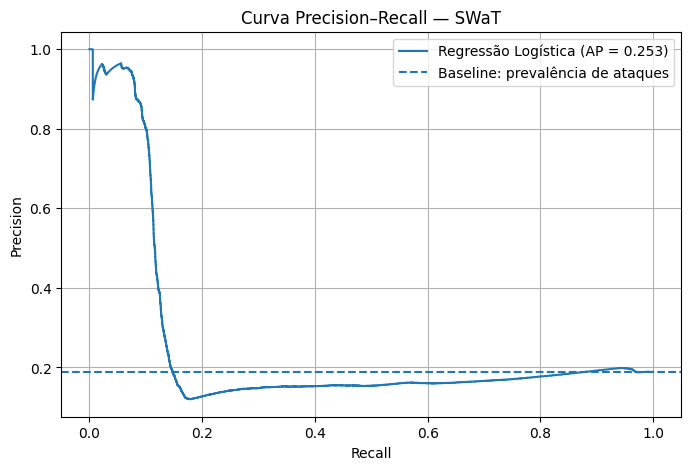

In [0]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Recolher apenas as colunas necessárias para a avaliação
df_metricas = df_scores.select(
    "label", "score_ataque"
).toPandas()

y_true = df_metricas["label"].to_numpy()
y_score = df_metricas["score_ataque"].to_numpy()

# Calcular a curva Precision-Recall
precision, recall, thresholds = precision_recall_curve(
    y_true, y_score
)

# Calcular Average Precision
ap = average_precision_score(y_true, y_score)

print(f"Average Precision (AP): {ap:.4f}")

# Desenhar a curva
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"Regressão Logística (AP = {ap:.3f})")
plt.axhline(
    y=np.mean(y_true),
    linestyle="--",
    label="Baseline: prevalência de ataques"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision–Recall — SWaT")
plt.legend()
plt.grid(True)
plt.show()

### Treinar o Random Forest

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier

# Preparar os sensores como vetor de características
assembler_rf = VectorAssembler(
    inputCols=sensores,
    outputCol="features",
    handleInvalid="error"
)

# Criar o classificador
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=50,
    maxDepth=10,
    seed=42
)

# Construir e treinar o pipeline
pipeline_rf = Pipeline(stages=[
    assembler_rf,
    rf
])

modelo_rf = pipeline_rf.fit(df_treino)

print("Random Forest treinado com sucesso.")

Random Forest treinado com sucesso.


Fazer previsões e calcular a AP

In [0]:
from pyspark.ml.functions import vector_to_array
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Gerar previsões no conjunto de teste
df_previsoes_rf = modelo_rf.transform(df_teste)

# Extrair a probabilidade estimada de ataque (classe 1)
df_scores_rf = df_previsoes_rf.withColumn(
    "score_ataque",
    vector_to_array("probability")[1]
)

# Calcular Average Precision com scikit-learn
from sklearn.metrics import average_precision_score

df_metricas_rf = df_scores_rf.select(
    "label", "score_ataque"
).toPandas()

y_true_rf = df_metricas_rf["label"].to_numpy()
y_score_rf = df_metricas_rf["score_ataque"].to_numpy()

ap_rf = average_precision_score(y_true_rf, y_score_rf)

# Calcular também PR-AUC pelo Spark
avaliador_pr_rf = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="score_ataque",
    metricName="areaUnderPR"
)

pr_auc_rf = avaliador_pr_rf.evaluate(df_scores_rf)

print(f"Random Forest — Average Precision (AP): {ap_rf:.4f}")
print(f"Random Forest — PR-AUC (Spark): {pr_auc_rf:.4f}")

Random Forest — Average Precision (AP): 0.8697
Random Forest — PR-AUC (Spark): 0.8707


avaliar o Random Forest com vários limiares

In [0]:
from pyspark.sql import functions as F

limiares_rf = [0.50, 0.40, 0.30, 0.20, 0.10, 0.05, 0.02]
resultados_rf = []

for limiar in limiares_rf:
    df_limiar = df_scores_rf.withColumn(
        "pred_limiar",
        (F.col("score_ataque") >= limiar).cast("int")
    )

    c = df_limiar.agg(
        F.sum(F.when((F.col("label") == 1) & (F.col("pred_limiar") == 1), 1).otherwise(0)).alias("TP"),
        F.sum(F.when((F.col("label") == 0) & (F.col("pred_limiar") == 1), 1).otherwise(0)).alias("FP"),
        F.sum(F.when((F.col("label") == 1) & (F.col("pred_limiar") == 0), 1).otherwise(0)).alias("FN"),
        F.sum(F.when((F.col("label") == 0) & (F.col("pred_limiar") == 0), 1).otherwise(0)).alias("TN")
    ).first()

    tp, fp = c["TP"], c["FP"]
    fn, tn = c["FN"], c["TN"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    fpr = fp / (fp + tn) if fp + tn else 0.0

    resultados_rf.append((
        float(limiar), int(tp), int(fp), int(fn), int(tn),
        float(precision), float(recall), float(f1), float(fpr)
    ))

df_limiares_rf = spark.createDataFrame(
    resultados_rf,
    ["limiar", "TP", "FP", "FN", "TN",
     "precision", "recall", "f1", "taxa_falsos_alarme"]
)

display(df_limiares_rf.orderBy("limiar", ascending=False))

limiar,TP,FP,FN,TN,precision,recall,f1,taxa_falsos_alarme
0.5,31786,127,11078,183728,0.9960204305455457,0.7415546845837999,0.8501544592588629,6.907617415898398E-4
0.4,32106,1227,10758,182628,0.963189631896319,0.7490201567749161,0.842710342926887,0.006673737456147508
0.3,33046,3688,9818,180167,0.8996025480481298,0.7709499813363195,0.8303223699087916,0.020059285850262436
0.2,34709,14561,8155,169294,0.7044651918002841,0.8097471071295259,0.7534460676840256,0.07919828125424927
0.1,36912,38358,5952,145497,0.4903945795137505,0.8611422172452408,0.6249174666057189,0.2086318022354573
0.05,37689,56388,5175,127467,0.4006186421760898,0.8792693169092946,0.5504414309812254,0.30669821326588886
0.02,39677,105527,3187,78328,0.27325004820803833,0.9256485628966032,0.4219431269540804,0.5739686165728427


##### Criar a divisão temporal
Vamos usar as datas que definimos:
- Treino: até 28 de dezembro de 2015.
- Validação: 29 e 30 de dezembro de 2015.
- Teste final: de 31 de dezembro de 2015 até 2 de janeiro de 2016.

In [0]:
from pyspark.sql import functions as F

# Ler os dados Gold deduplicados
df_base = spark.table("first_catalog.default.gold_swat_ml_dedup")

# Criar a variável alvo: ATTACK = 1, NORMAL = 0
df_base = df_base.withColumn(
    "label",
    F.when(F.col("normal_attack") == "ATTACK", 1.0)
     .otherwise(0.0)
)

# Divisão temporal
df_treino_v2 = df_base.filter(
    F.to_date("Timestamp") <= F.lit("2015-12-28")
)

df_validacao = df_base.filter(
    (F.to_date("Timestamp") >= F.lit("2015-12-29")) &
    (F.to_date("Timestamp") <= F.lit("2015-12-30"))
)

df_teste_final = df_base.filter(
    F.to_date("Timestamp") >= F.lit("2015-12-31")
)

# Confirmar dimensões e distribuição das classes
for nome, df in [
    ("Treino", df_treino_v2),
    ("Validação", df_validacao),
    ("Teste final", df_teste_final)
]:
    print(f"\n{nome}")
    print(f"Total de linhas: {df.count():,}")
    display(
        df.groupBy("normal_attack")
          .count()
          .orderBy("normal_attack")
    )


Treino
Total de linhas: 547,200


normal_attack,count
ATTACK,4466
NORMAL,542734



Validação
Total de linhas: 172,800


normal_attack,count
ATTACK,7291
NORMAL,165509



Teste final
Total de linhas: 226,719


normal_attack,count
ATTACK,42864
NORMAL,183855


Verificar as classes

In [0]:
from pyspark.sql import functions as F

def resumo_classes(df, nome):
    return (
        df.groupBy("normal_attack")
          .agg(F.count("*").alias("linhas"))
          .withColumn(
              "conjunto",
              F.lit(nome)
          )
          .withColumn(
              "percentagem",
              F.round(
                  F.col("linhas") /
                  F.sum("linhas").over(
                      __import__("pyspark").sql.Window
                      .partitionBy("conjunto")
                  ) * 100,
                  2
              )
          )
    )

resumo = (
    resumo_classes(df_treino_v2, "Treino")
    .unionByName(resumo_classes(df_validacao, "Validação"))
    .unionByName(resumo_classes(df_teste_final, "Teste final"))
)

display(
    resumo.select(
        "conjunto", "normal_attack", "linhas", "percentagem"
    ).orderBy("conjunto", "normal_attack")
)

conjunto,normal_attack,linhas,percentagem
Teste final,ATTACK,42864,18.91
Teste final,NORMAL,183855,81.09
Treino,ATTACK,4466,0.82
Treino,NORMAL,542734,99.18
Validação,ATTACK,7291,4.22
Validação,NORMAL,165509,95.78


Treinar novamente o Random Forest

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier

# Selecionar as colunas dos sensores
colunas_excluir = ["Timestamp", "normal_attack", "label"]

sensores_v2 = [
    c for c in df_treino_v2.columns
    if c not in colunas_excluir
]

# Criar o vetor de características
assembler_rf_v2 = VectorAssembler(
    inputCols=sensores_v2,
    outputCol="features",
    handleInvalid="error"
)

# Configurar o Random Forest
rf_v2 = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=50,
    maxDepth=10,
    seed=42
)

# Construir e treinar o pipeline
pipeline_rf_v2 = Pipeline(stages=[
    assembler_rf_v2,
    rf_v2
])

modelo_rf_v2 = pipeline_rf_v2.fit(df_treino_v2)

print("Random Forest treinado com a nova divisão temporal.")
print(f"Número de sensores utilizados: {len(sensores_v2)}")

Random Forest treinado com a nova divisão temporal.
Número de sensores utilizados: 44


In [0]:
from pyspark.ml.functions import vector_to_array
from pyspark.ml.evaluation import BinaryClassificationEvaluator

from sklearn.metrics import average_precision_score

# Fazer previsões na validação
df_previsoes_validacao = modelo_rf_v2.transform(df_validacao)

# Extrair a probabilidade de ataque
df_scores_validacao = df_previsoes_validacao.withColumn(
    "score_ataque",
    vector_to_array("probability")[1]
)

# Calcular Average Precision
df_metricas_validacao = df_scores_validacao.select(
    "label", "score_ataque"
).toPandas()

y_validacao = df_metricas_validacao["label"].to_numpy()
scores_validacao = df_metricas_validacao["score_ataque"].to_numpy()

ap_validacao = average_precision_score(
    y_validacao,
    scores_validacao
)

# Calcular PR-AUC pelo Spark
avaliador_pr = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="score_ataque",
    metricName="areaUnderPR"
)

pr_auc_validacao = avaliador_pr.evaluate(
    df_scores_validacao
)

print(f"Average Precision na validação: {ap_validacao:.4f}")
print(f"PR-AUC na validação (Spark): {pr_auc_validacao:.4f}")
print(f"Prevalência de ataques: {y_validacao.mean():.2%}")

Average Precision na validação: 0.3431
PR-AUC na validação (Spark): 0.3407
Prevalência de ataques: 4.22%


A AP de 0,3431 é aproximadamente 8,1 vezes superior à prevalência de ataques na validação. É um sinal promissor, embora não garanta, por si só, um bom desempenho operacional.
Os resultados também mostram por que foi importante criar a divisão temporal: a AP de validação (0,3431) é bastante inferior à AP do modelo anterior no teste (0,8697). Como os modelos foram treinados com divisões diferentes, não devemos atribuir essa diferença apenas à qualidade do algoritmo.
#### escolher o limiar na validação
Agora vamos comparar os limiares na validação. O objetivo será encontrar um compromisso entre detetar ataques e limitar falsos alarmes, sem consultar o teste final.

In [0]:
from pyspark.sql import functions as F

limiares_validacao = [
    0.50, 0.40, 0.30, 0.20, 0.10, 0.05, 0.02, 0.01
]

resultados_validacao = []

for limiar in limiares_validacao:
    df_limiar = df_scores_validacao.withColumn(
        "pred_limiar",
        (F.col("score_ataque") >= limiar).cast("int")
    )

    c = df_limiar.agg(
        F.sum(F.when(
            (F.col("label") == 1) & (F.col("pred_limiar") == 1), 1
        ).otherwise(0)).alias("TP"),
        F.sum(F.when(
            (F.col("label") == 0) & (F.col("pred_limiar") == 1), 1
        ).otherwise(0)).alias("FP"),
        F.sum(F.when(
            (F.col("label") == 1) & (F.col("pred_limiar") == 0), 1
        ).otherwise(0)).alias("FN"),
        F.sum(F.when(
            (F.col("label") == 0) & (F.col("pred_limiar") == 0), 1
        ).otherwise(0)).alias("TN")
    ).first()

    tp, fp = c["TP"], c["FP"]
    fn, tn = c["FN"], c["TN"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    fpr = fp / (fp + tn) if fp + tn else 0.0

    resultados_validacao.append((
        float(limiar), int(tp), int(fp), int(fn), int(tn),
        float(precision), float(recall), float(f1), float(fpr)
    ))

df_resultados_validacao = spark.createDataFrame(
    resultados_validacao,
    [
        "limiar", "TP", "FP", "FN", "TN",
        "precision", "recall", "f1", "taxa_falsos_alarme"
    ]
)

display(df_resultados_validacao.orderBy("limiar", ascending=False))

limiar,TP,FP,FN,TN,precision,recall,f1,taxa_falsos_alarme
0.5,482,0,6809,165509,1.0,0.06610890138526951,0.12401904026759293,0.0
0.4,902,22,6389,165487,0.9761904761904762,0.1237141681525168,0.2195982958003652,1.3292328513857252E-4
0.3,1482,1153,5809,164356,0.5624288425047438,0.20326429845014402,0.29860971186782187,0.0069663885347624604
0.2,3847,15722,3444,149787,0.19658643773314938,0.5276368125085722,0.2864482501861504,0.09499181313402896
0.1,5325,57309,1966,108200,0.08501772200402337,0.7303524893704567,0.15230604218805863,0.3462591158184751
0.05,6505,99326,786,66183,0.06146592208332152,0.8921958579070086,0.1150085748130337,0.6001244645306297
0.02,7243,133002,48,32507,0.05164533494955257,0.993416540940886,0.09818620540071575,0.8035937622727465
0.01,7278,136460,13,29049,0.050633792038291894,0.9982169798381566,0.09637884114971297,0.8244868859095276


A minha recomendação para este projeto: escolher inicialmente o limiar 0,30, porque apresenta o melhor F1 entre os limiares avaliados. É uma escolha experimental, não necessariamente a melhor decisão operacional. Se o custo de não detetar um ataque for muito superior ao custo de investigar um falso alarme, poderemos preferir outro limiar.
Há uma limitação importante: a prevalência de ataques aumenta de 0,82% no treino para 4,22% na validação e 18,91% no teste final. Esta alteração temporal pode afetar significativamente o desempenho e a transferência do limiar.
##### Fixar o limiar e avaliar o teste final
Vamos fixar o limiar em 0.30 e avaliar o conjunto de teste final apenas agora. Não devemos voltar a ajustar o limiar com base nos resultados do teste.

In [0]:
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# Limiar escolhido exclusivamente com base na validação
limiar_final = 0.30

# Gerar previsões no conjunto de teste final
df_previsoes_teste = modelo_rf_v2.transform(df_teste_final)

# Extrair a probabilidade prevista para ATTACK
df_scores_teste = df_previsoes_teste.withColumn(
    "score_ataque",
    vector_to_array("probability")[1]
)

# Aplicar o limiar fixado
df_avaliacao_final = df_scores_teste.withColumn(
    "pred_final",
    (F.col("score_ataque") >= limiar_final).cast("int")
)

# Matriz de confusão
c = df_avaliacao_final.agg(
    F.sum(F.when(
        (F.col("label") == 1) & (F.col("pred_final") == 1), 1
    ).otherwise(0)).alias("TP"),
    F.sum(F.when(
        (F.col("label") == 0) & (F.col("pred_final") == 1), 1
    ).otherwise(0)).alias("FP"),
    F.sum(F.when(
        (F.col("label") == 1) & (F.col("pred_final") == 0), 1
    ).otherwise(0)).alias("FN"),
    F.sum(F.when(
        (F.col("label") == 0) & (F.col("pred_final") == 0), 1
    ).otherwise(0)).alias("TN")
).first()

tp, fp, fn, tn = c["TP"], c["FP"], c["FN"], c["TN"]

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)
taxa_falsos_alarme = fp / (fp + tn) if fp + tn else 0.0

print(f"Limiar fixado: {limiar_final:.2f}")
print(f"TP: {tp}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TN: {tn}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"Taxa de falsos alarmes: {taxa_falsos_alarme:.4f}")

Limiar fixado: 0.30
TP: 33962
FP: 24973
FN: 8902
TN: 158882
Precision: 0.5763
Recall: 0.7923
F1: 0.6672
Taxa de falsos alarmes: 0.1358
